# **Machine learning models**

This notebook trains three models (logistic regression, random forest and decision tree) on the HCV data in three ways: healthy or sick, four classes with SMOTE, and hepatitis, fibrosis or cirrhosis among sick patients only. The models, their settings and the evaluation are the same as in `COM725/COM725_AE2_Omar_Al_Hajaj.ipynb`, so the two studies can be compared.

Missing values are left in the data. Each model starts with a median imputer inside a pipeline, so the median is learned from the training rows only and nothing from the test rows leaks into training.

Two things differ from COM725. Outliers are kept, because in this data the extreme values belong to the sick patients (see `cleaning.ipynb`). The decision tree is trained on the original values and not on binned values, because the COM725 bins were written for a different set of columns.

# **Importing Libraries**

In [1]:
# importing necessary libraries / dependencies
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (LabelEncoder, QuantileTransformer,
                                   label_binarize)
from sklearn.tree import DecisionTreeClassifier

pd.set_option('display.max_columns', None)

# **Loading the DataFrame**

In [2]:
# retrieving the raw dataset (missing values are left in)
df = pd.read_csv('hcvdat0.csv')

# dropping the row number column
df = df.drop(columns=['Unnamed: 0'])

# removing the number before the = sign in the labels
df['Category'] = df['Category'].str.replace(r'^[^=]*=', '', regex=True)

# removing suspect blood donors
df = df[~df['Category'].str.contains('suspect', case=False)]

# renaming blood donors to healthy
df['Category'] = df['Category'].replace('Blood Donor', 'Healthy')

# checking that 608 patients are left
assert df['Category'].value_counts().to_dict() == {
    'Healthy': 533, 'Cirrhosis': 30, 'Hepatitis': 24, 'Fibrosis': 21}
print(df['Category'].value_counts())

# first 5 rows of the dataset
df.head()

Category
Healthy      533
Cirrhosis     30
Hepatitis     24
Fibrosis      21
Name: count, dtype: int64


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,Healthy,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,Healthy,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,Healthy,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,Healthy,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,Healthy,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


# **Feature engineering**

FIB-4 was added to the COM725 data, but it needs a platelet count and this dataset does not have one. The AST/ALT ratio is used here instead, because it only needs two columns that are already in the data.

Sheth et al. (1998) found that the AST/ALT ratio is higher in chronic hepatitis C patients with cirrhosis (mean 1.06) than in those without (mean 0.60). Chicco and Jurman (2021) trained machine learning models on this same dataset and found AST and ALT to be the two most useful variables, which are the two values the ratio is made of.

- Sheth, S.G., Flamm, S.L., Gordon, F.D. and Chopra, S. (1998) 'AST/ALT ratio predicts cirrhosis in patients with chronic hepatitis C virus infection', *American Journal of Gastroenterology*, 93(1), pp. 44-48.
- Chicco, D. and Jurman, G. (2021) 'An ensemble learning approach for enhanced classification of patients with hepatitis and cirrhosis', *IEEE Access*, 9, pp. 24485-24498.

In [3]:
# engineering the AST/ALT ratio
df['ast_alt_ratio'] = df['AST'] / df['ALT']

# making sure the division did not create infinite values
# one patient has no ALT, so one ratio is missing and is imputed later
assert not np.isinf(df['ast_alt_ratio']).any()
print('Missing ratios:', df['ast_alt_ratio'].isna().sum())

# checking the new feature for each category
df.groupby('Category')['ast_alt_ratio'].describe()

Missing ratios: 1


,count,mean,std,min,25%,50%,75%,max
Category,,,,,,,,
Cirrhosis,30.0,16.844175,17.037207,0.638298,6.541667,14.927027,20.582749,89.222222
Fibrosis,21.0,4.728592,7.358996,0.410853,0.809524,3.580311,5.411255,34.791667
Healthy,533.0,1.153575,0.761765,0.417443,0.853175,1.083333,1.319635,15.840000
Hepatitis,23.0,3.791468,2.299543,0.681818,2.946773,3.639098,4.532734,11.654676


# **Target engineering**

In [4]:
# grouping hepatitis, fibrosis and cirrhosis patients into one sick class
df['Target'] = np.where(df['Category'] == 'Healthy', 'Healthy', 'Sick')

# number of patients in each class
print(df['Target'].value_counts())

Target
Healthy    533
Sick        75
Name: count, dtype: int64


# **Machine learning training and modelling**

# Encoding and data preparation

In [5]:
# encoding sex into numeric values (f = 0, m = 1)
sex_encoder = LabelEncoder()
df['Sex'] = sex_encoder.fit_transform(df['Sex'])

# encoding the target into numeric values (Healthy = 0, Sick = 1)
target_encoder = LabelEncoder()
df['Target'] = target_encoder.fit_transform(df['Target'])
classes = target_encoder.classes_
print(classes)

['Healthy' 'Sick']


In [6]:
# defining training and target features
# Category is dropped as it holds the diagnosis itself

X = df.drop(columns=['Category', 'Target'])
y = df['Target']

# train - test split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# checking the size of each set and the number of sick patients in it
print('Train:', X_train.shape, 'sick patients:', y_train.sum())
print('Test:', X_test.shape, 'sick patients:', y_test.sum())

Train: (486, 13) sick patients: 60
Test: (122, 13) sick patients: 15


# Logistic regression

In [7]:
# defining logistic regression pipeline
# the imputer learns the median from the training rows only
# n_quantiles is set to the number of training rows as it cannot be larger
log_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transformer', QuantileTransformer(
        n_quantiles=len(X_train),
        output_distribution='normal',
        random_state=42)),
    ('classifier', LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42))])

# training pipeline
log_pipeline.fit(X_train, y_train)

# testing pipeline
log_preds = log_pipeline.predict(X_test)

# evaluating predictions
log_results = classification_report(y_test, log_preds, target_names=classes)
print(log_results)

              precision    recall  f1-score   support

     Healthy       0.98      0.99      0.99       107
        Sick       0.93      0.87      0.90        15

    accuracy                           0.98       122
   macro avg       0.96      0.93      0.94       122
weighted avg       0.97      0.98      0.98       122



The model performs well, with 98% accuracy. It finds 13 of the 15 sick patients and wrongly flags 1 of the 107 healthy patients.

# Calibration plot - Logistic Regression

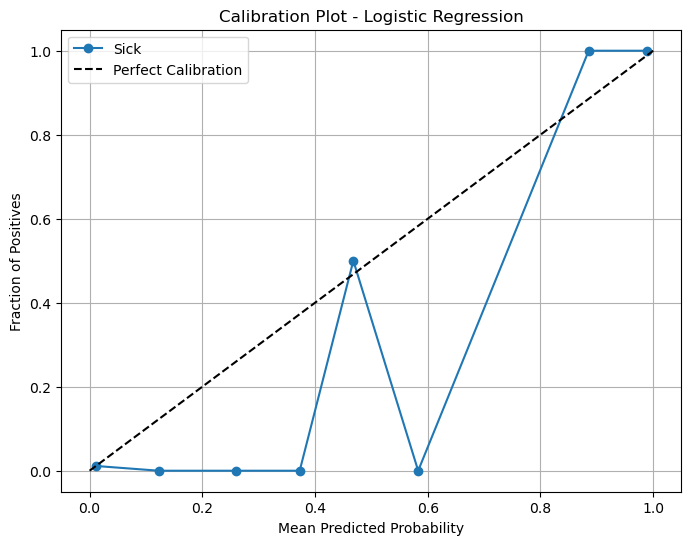

In [8]:
# getting predicted probabilities of the sick class from logistic regression
log_probs = log_pipeline.predict_proba(X_test)[:, 1]

# calculate calibration curve for the sick class
prob_true, prob_pred = calibration_curve(
    y_test,
    log_probs,
    n_bins=10,
    strategy='uniform'
)

# plotting calibration curve
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Sick')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Logistic Regression')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature distribution - logistic regression

Data preparation

In [9]:
# creating a copy of the test data
log_error_df = X_test.copy()

# adding actual and predicted classes
log_error_df['Actual_Class'] = y_test.values
log_error_df['Predicted_Class'] = log_preds

# checking if the prediction was correct or incorrect
log_error_df['Prediction_Result'] = np.where(
    log_error_df['Actual_Class'] == log_error_df['Predicted_Class'],
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(log_error_df['Prediction_Result'].value_counts())

Prediction_Result
Correct      119
Incorrect      3
Name: count, dtype: int64


Error plots - logistic regression

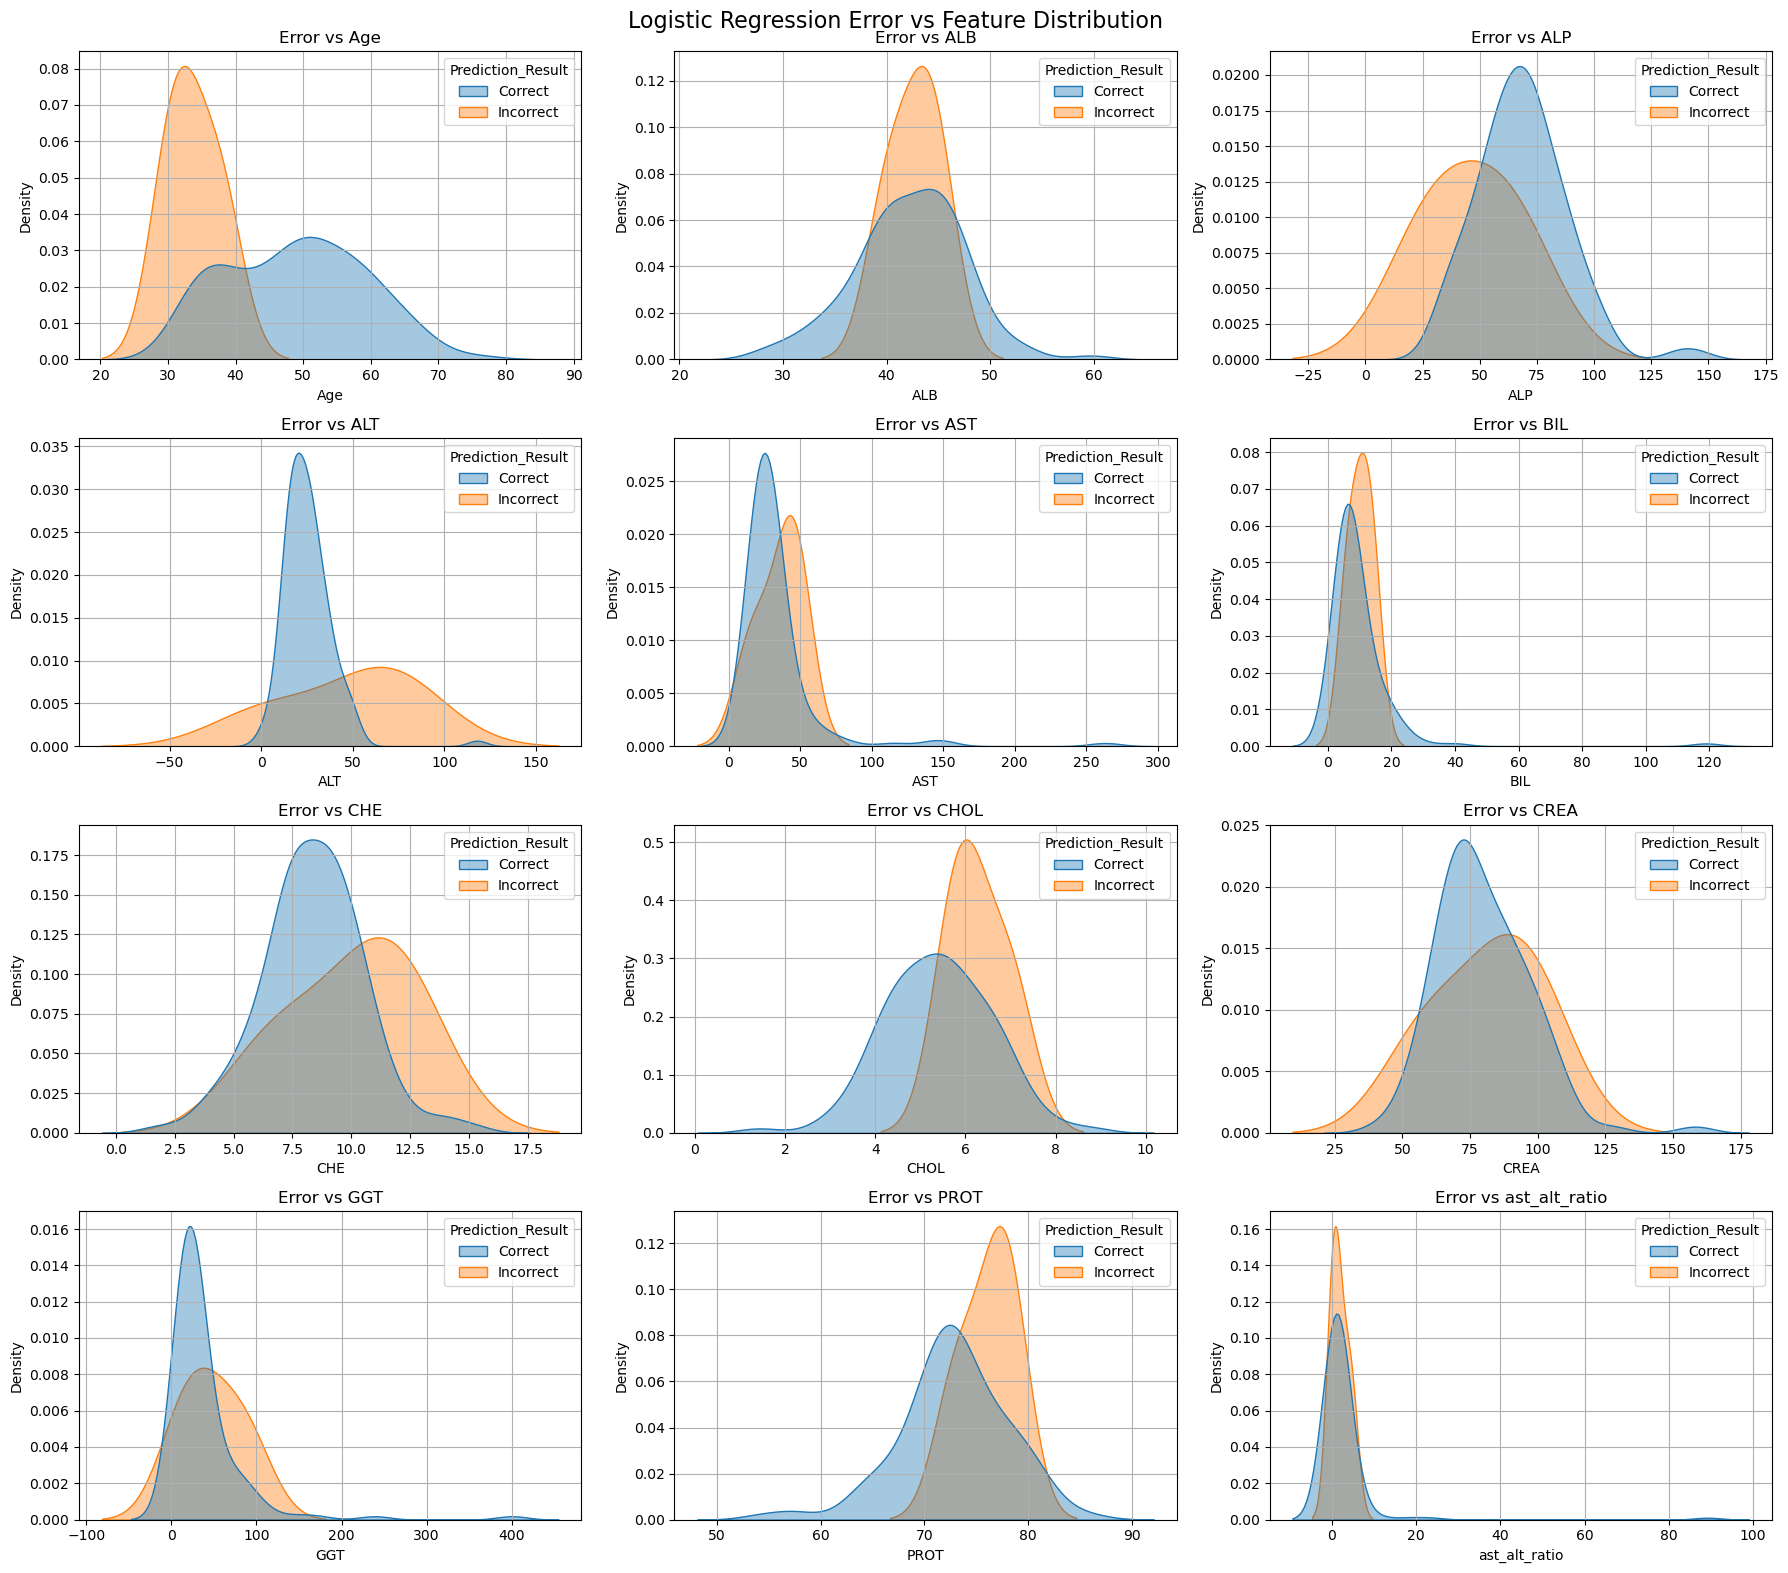

In [10]:
# choosing selected features to inspect (sex is left out as it is binary)
features_to_plot = [col for col in X_train.columns if col != 'Sex']

# setting number of plots per row
plots_per_row = 3

# calculating number of rows needed
n_rows = math.ceil(len(features_to_plot) / plots_per_row)

# creating subplots
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=log_error_df,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Logistic Regression Error vs Feature Distribution',
             fontsize=16)
plt.tight_layout()
plt.show()

# Random forest

In [11]:
# defining random forest pipeline
rf_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=200,        # number of trees
        max_depth=None,          # let trees grow fully
        min_samples_split=2,     # minimum samples to split
        min_samples_leaf=1,      # minimum samples per leaf
        max_features='sqrt',     # features considered per split
        class_weight='balanced',
        random_state=42,
        n_jobs=-1))])

# training model
rf_model.fit(X_train, y_train)

# predictions
rf_preds = rf_model.predict(X_test)

# evaluating predictions
rf_results = classification_report(y_test, rf_preds, target_names=classes)
print(rf_results)

              precision    recall  f1-score   support

     Healthy       0.98      0.99      0.99       107
        Sick       0.93      0.87      0.90        15

    accuracy                           0.98       122
   macro avg       0.96      0.93      0.94       122
weighted avg       0.97      0.98      0.98       122



The random forest gives the same result as logistic regression: 98% accuracy, 13 of the 15 sick patients found and 1 healthy patient wrongly flagged.

# Calibration plot - Random Forest

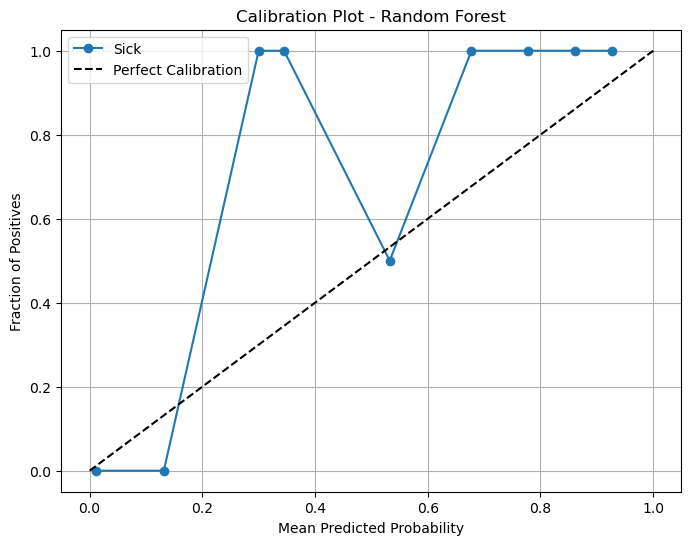

In [12]:
# getting predicted probabilities of the sick class from random forest
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# calculate calibration curve for the sick class
prob_true, prob_pred = calibration_curve(
    y_test,
    rf_probs,
    n_bins=10,
    strategy='uniform'
)

# plotting calibration curve
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Sick')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Random Forest')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature plot - random forest

Data preparation

In [13]:
# creating a copy of the test data
rf_error_df = X_test.copy()

# adding actual and predicted classes
rf_error_df['Actual_Class'] = y_test.values
rf_error_df['Predicted_Class'] = rf_preds

# checking if the prediction was correct or incorrect
rf_error_df['Prediction_Result'] = np.where(
    rf_error_df['Actual_Class'] == rf_error_df['Predicted_Class'],
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(rf_error_df['Prediction_Result'].value_counts())

Prediction_Result
Correct      119
Incorrect      3
Name: count, dtype: int64


Error plots - random forest

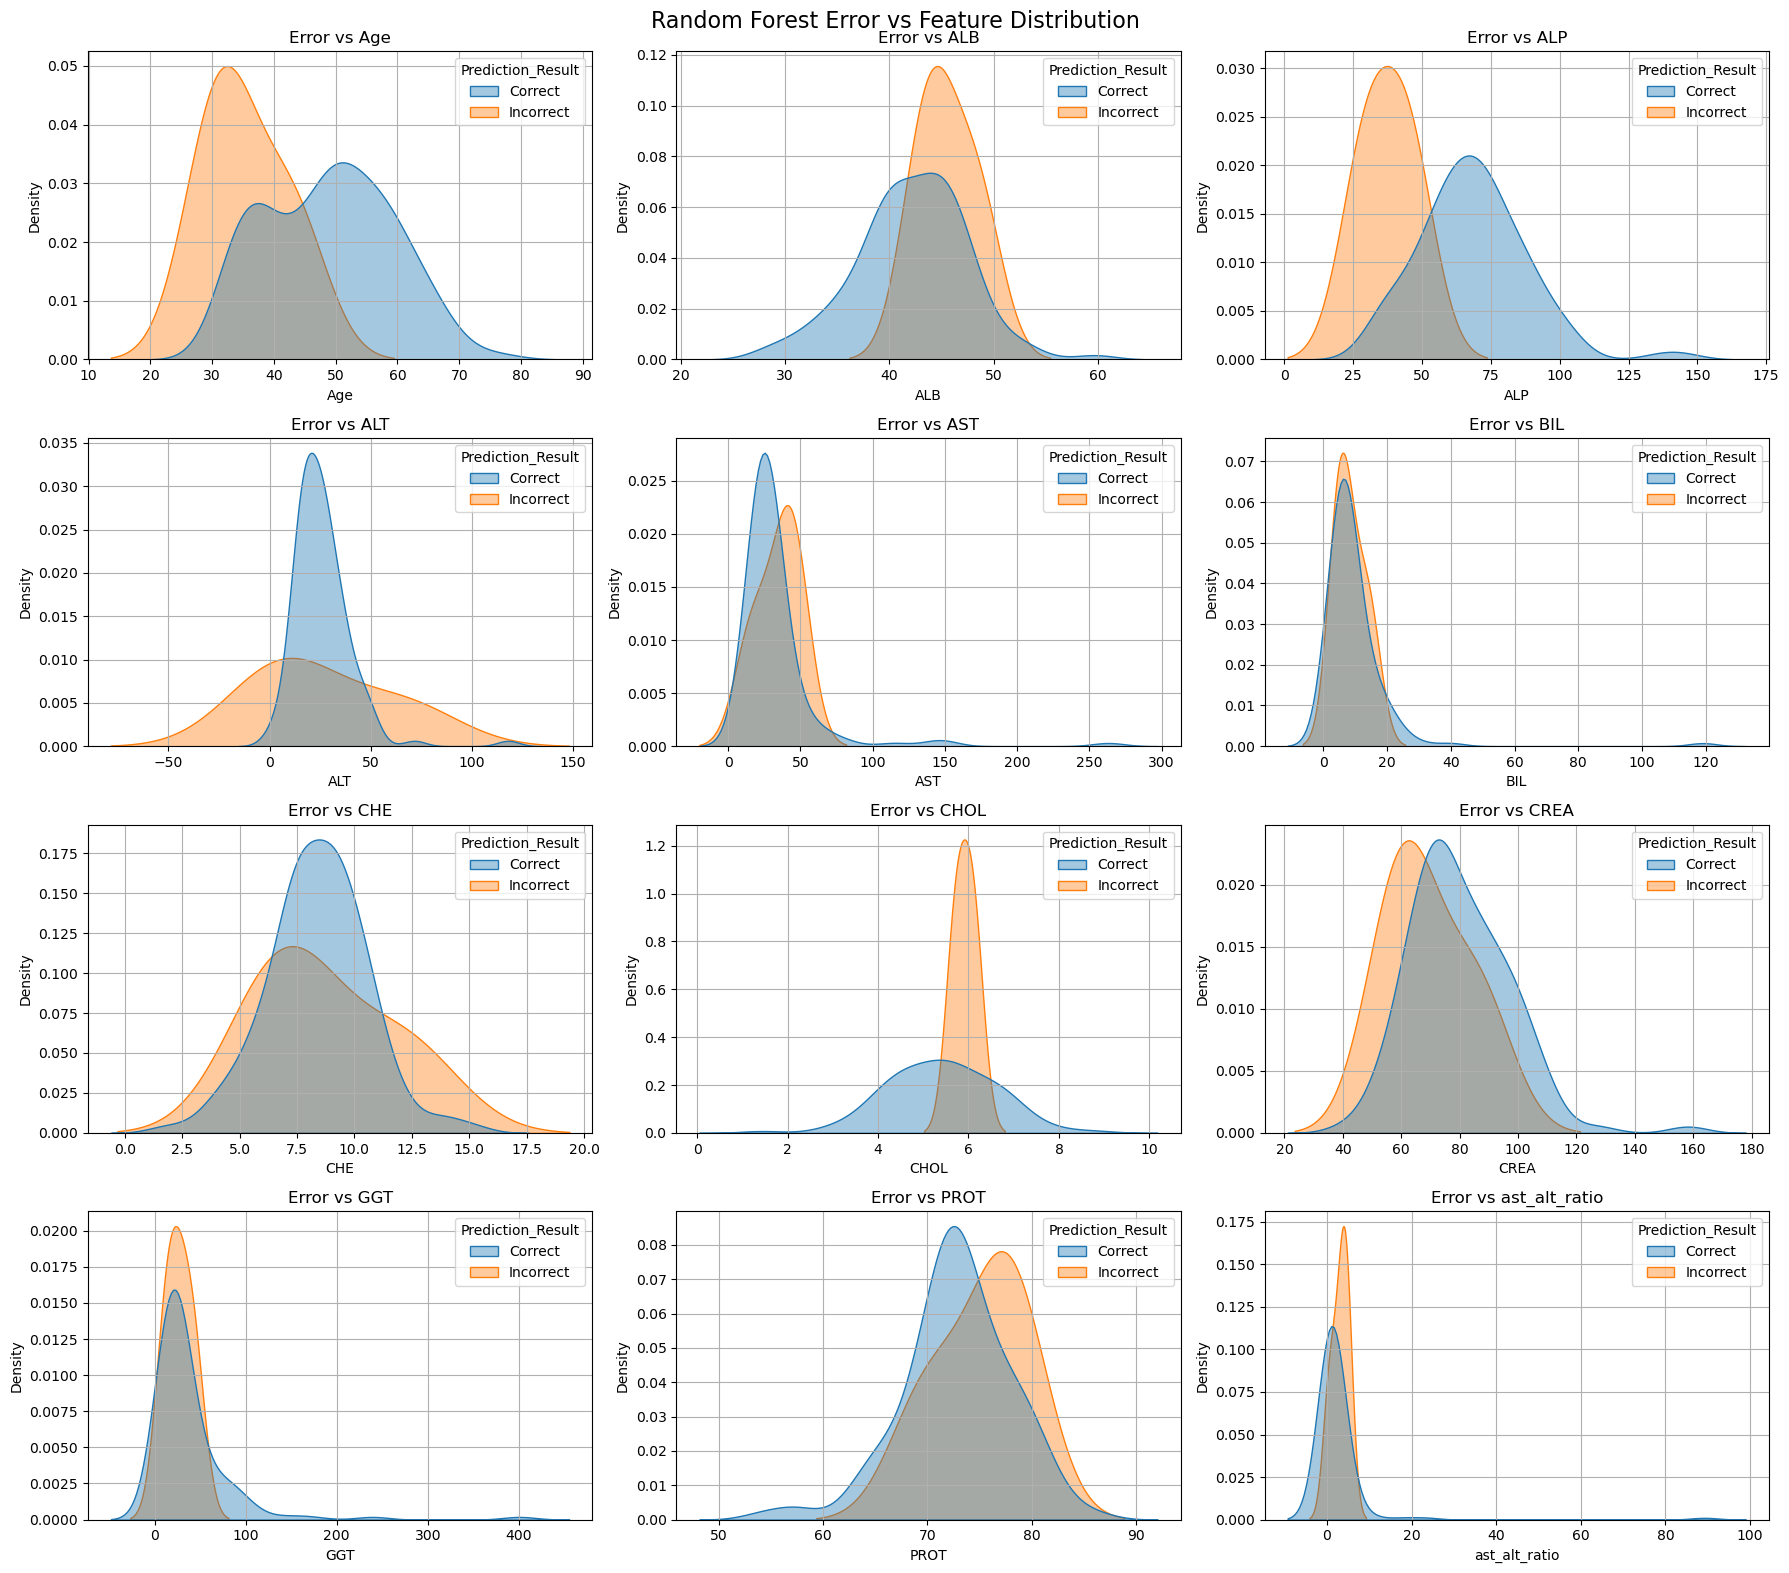

In [14]:
# creating subplots (same features and layout as logistic regression)
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=rf_error_df,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Random Forest Error vs Feature Distribution', fontsize=16)
plt.tight_layout()
plt.show()

# Decision tree

In [15]:
# defining decision tree pipeline
dt_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'))])

# training model
dt_model.fit(X_train, y_train)

# predictions
dt_preds = dt_model.predict(X_test)

# evaluating predictions
print('Accuracy:', accuracy_score(y_test, dt_preds))
print(classification_report(y_test, dt_preds, target_names=classes))

Accuracy: 0.9836065573770492
              precision    recall  f1-score   support

     Healthy       1.00      0.98      0.99       107
        Sick       0.88      1.00      0.94        15

    accuracy                           0.98       122
   macro avg       0.94      0.99      0.96       122
weighted avg       0.99      0.98      0.98       122



The decision tree finds all 15 sick patients and wrongly flags 2 of the 107 healthy patients, which also gives 98% accuracy.

# Calibration plot - Decision Tree

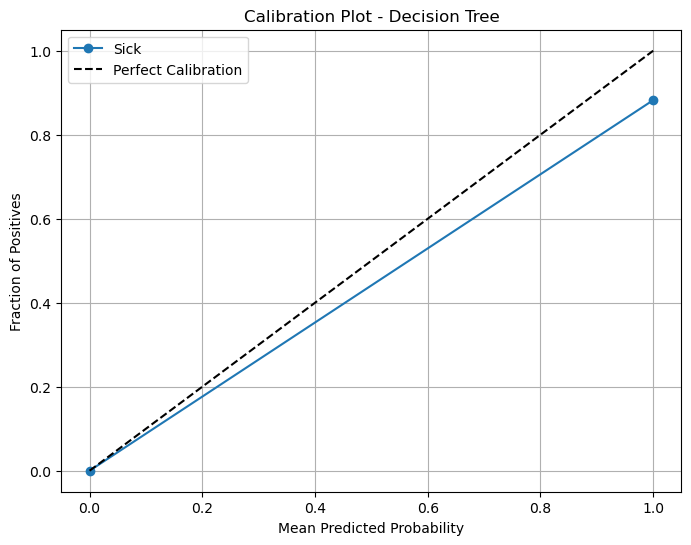

In [16]:
# getting predicted probabilities of the sick class from decision tree
dt_probs = dt_model.predict_proba(X_test)[:, 1]

# calculate calibration curve for the sick class
prob_true, prob_pred = calibration_curve(
    y_test,
    dt_probs,
    n_bins=10,
    strategy='uniform'
)

# plotting calibration curve
plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Sick')

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Decision Tree')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# **Four-class models with SMOTE**

These models predict Healthy, Hepatitis, Fibrosis or Cirrhosis. The classes are very uneven, so SMOTE creates synthetic patients for the small classes. SMOTE is a step inside the pipeline, so it only ever sees training rows, and the test set holds real patients only.

# Data preparation

In [17]:
# encoding the four classes into numeric values
encoder_4c = LabelEncoder()
y_4c = encoder_4c.fit_transform(df['Category'])
classes_4c = encoder_4c.classes_
print(classes_4c)

# same feature columns as the binary models
X_4c = X.copy()

# position of the sex column, as SMOTENC treats it as categorical
sex_position = [list(X_4c.columns).index('Sex')]

# train - test split
X_train_4c, X_test_4c, y_train_4c, y_test_4c = train_test_split(
    X_4c, y_4c, test_size=0.2, random_state=42, stratify=y_4c
)

# class counts of the training set before smote
print(pd.Series(y_train_4c).map(dict(enumerate(classes_4c))).value_counts())

# class counts of the test set (never resampled)
print(pd.Series(y_test_4c).map(dict(enumerate(classes_4c))).value_counts())

# binarising the test labels for the calibration plots
y_test_bin_4c = label_binarize(y_test_4c, classes=range(len(classes_4c)))

['Cirrhosis' 'Fibrosis' 'Healthy' 'Hepatitis']
Healthy      426
Cirrhosis     24
Hepatitis     19
Fibrosis      17
Name: count, dtype: int64
Healthy      107
Cirrhosis      6
Hepatitis      5
Fibrosis       4
Name: count, dtype: int64


# Logistic regression

In [18]:
# defining logistic regression pipeline
# smote comes after the imputer and before the quantile transformer
log_pipeline_4c = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTENC(
        categorical_features=sex_position,
        k_neighbors=5,
        random_state=42)),
    ('transformer', QuantileTransformer(
        output_distribution='normal',
        random_state=42)),
    ('classifier', LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42))])

# training pipeline
log_pipeline_4c.fit(X_train_4c, y_train_4c)

# testing pipeline
log_preds_4c = log_pipeline_4c.predict(X_test_4c)

# evaluating predictions
log_results_4c = classification_report(
    y_test_4c, log_preds_4c, target_names=classes_4c)
print(log_results_4c)

              precision    recall  f1-score   support

   Cirrhosis       0.57      0.67      0.62         6
    Fibrosis       0.25      0.25      0.25         4
     Healthy       0.98      0.97      0.98       107
   Hepatitis       0.60      0.60      0.60         5

    accuracy                           0.92       122
   macro avg       0.60      0.62      0.61       122
weighted avg       0.92      0.92      0.92       122



Accuracy is 92%, but most of the test patients are healthy. The model finds 4 of the 6 cirrhosis, 3 of the 5 hepatitis and 1 of the 4 fibrosis patients, and wrongly flags 3 of the 107 healthy patients.

# Calibration plot - Logistic Regression

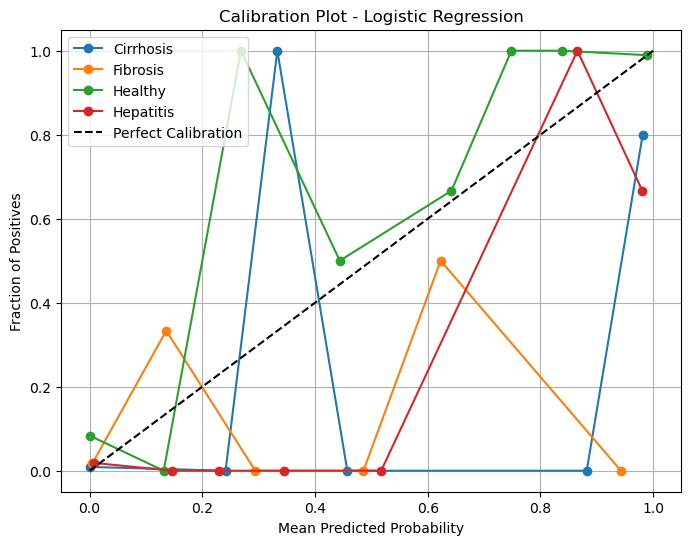

In [19]:
# getting predicted probabilities of every class from Logistic Regression
log_probs_4c = log_pipeline_4c.predict_proba(X_test_4c)

# plotting calibration curves
plt.figure(figsize=(8, 6))

# loop through each class
for i, class_name in enumerate(classes_4c):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin_4c[:, i],
        log_probs_4c[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=class_name)

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Logistic Regression')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature distribution - logistic regression

Data preparation

In [20]:
# creating a copy of the test data
log_error_df_4c = X_test_4c.copy()

# adding actual and predicted classes
log_error_df_4c['Actual_Class'] = y_test_4c
log_error_df_4c['Predicted_Class'] = log_preds_4c

# checking if the prediction was correct or incorrect
log_error_df_4c['Prediction_Result'] = np.where(
    y_test_4c == log_preds_4c,
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(log_error_df_4c['Prediction_Result'].value_counts())

Prediction_Result
Correct      112
Incorrect     10
Name: count, dtype: int64


Error plots - logistic regression

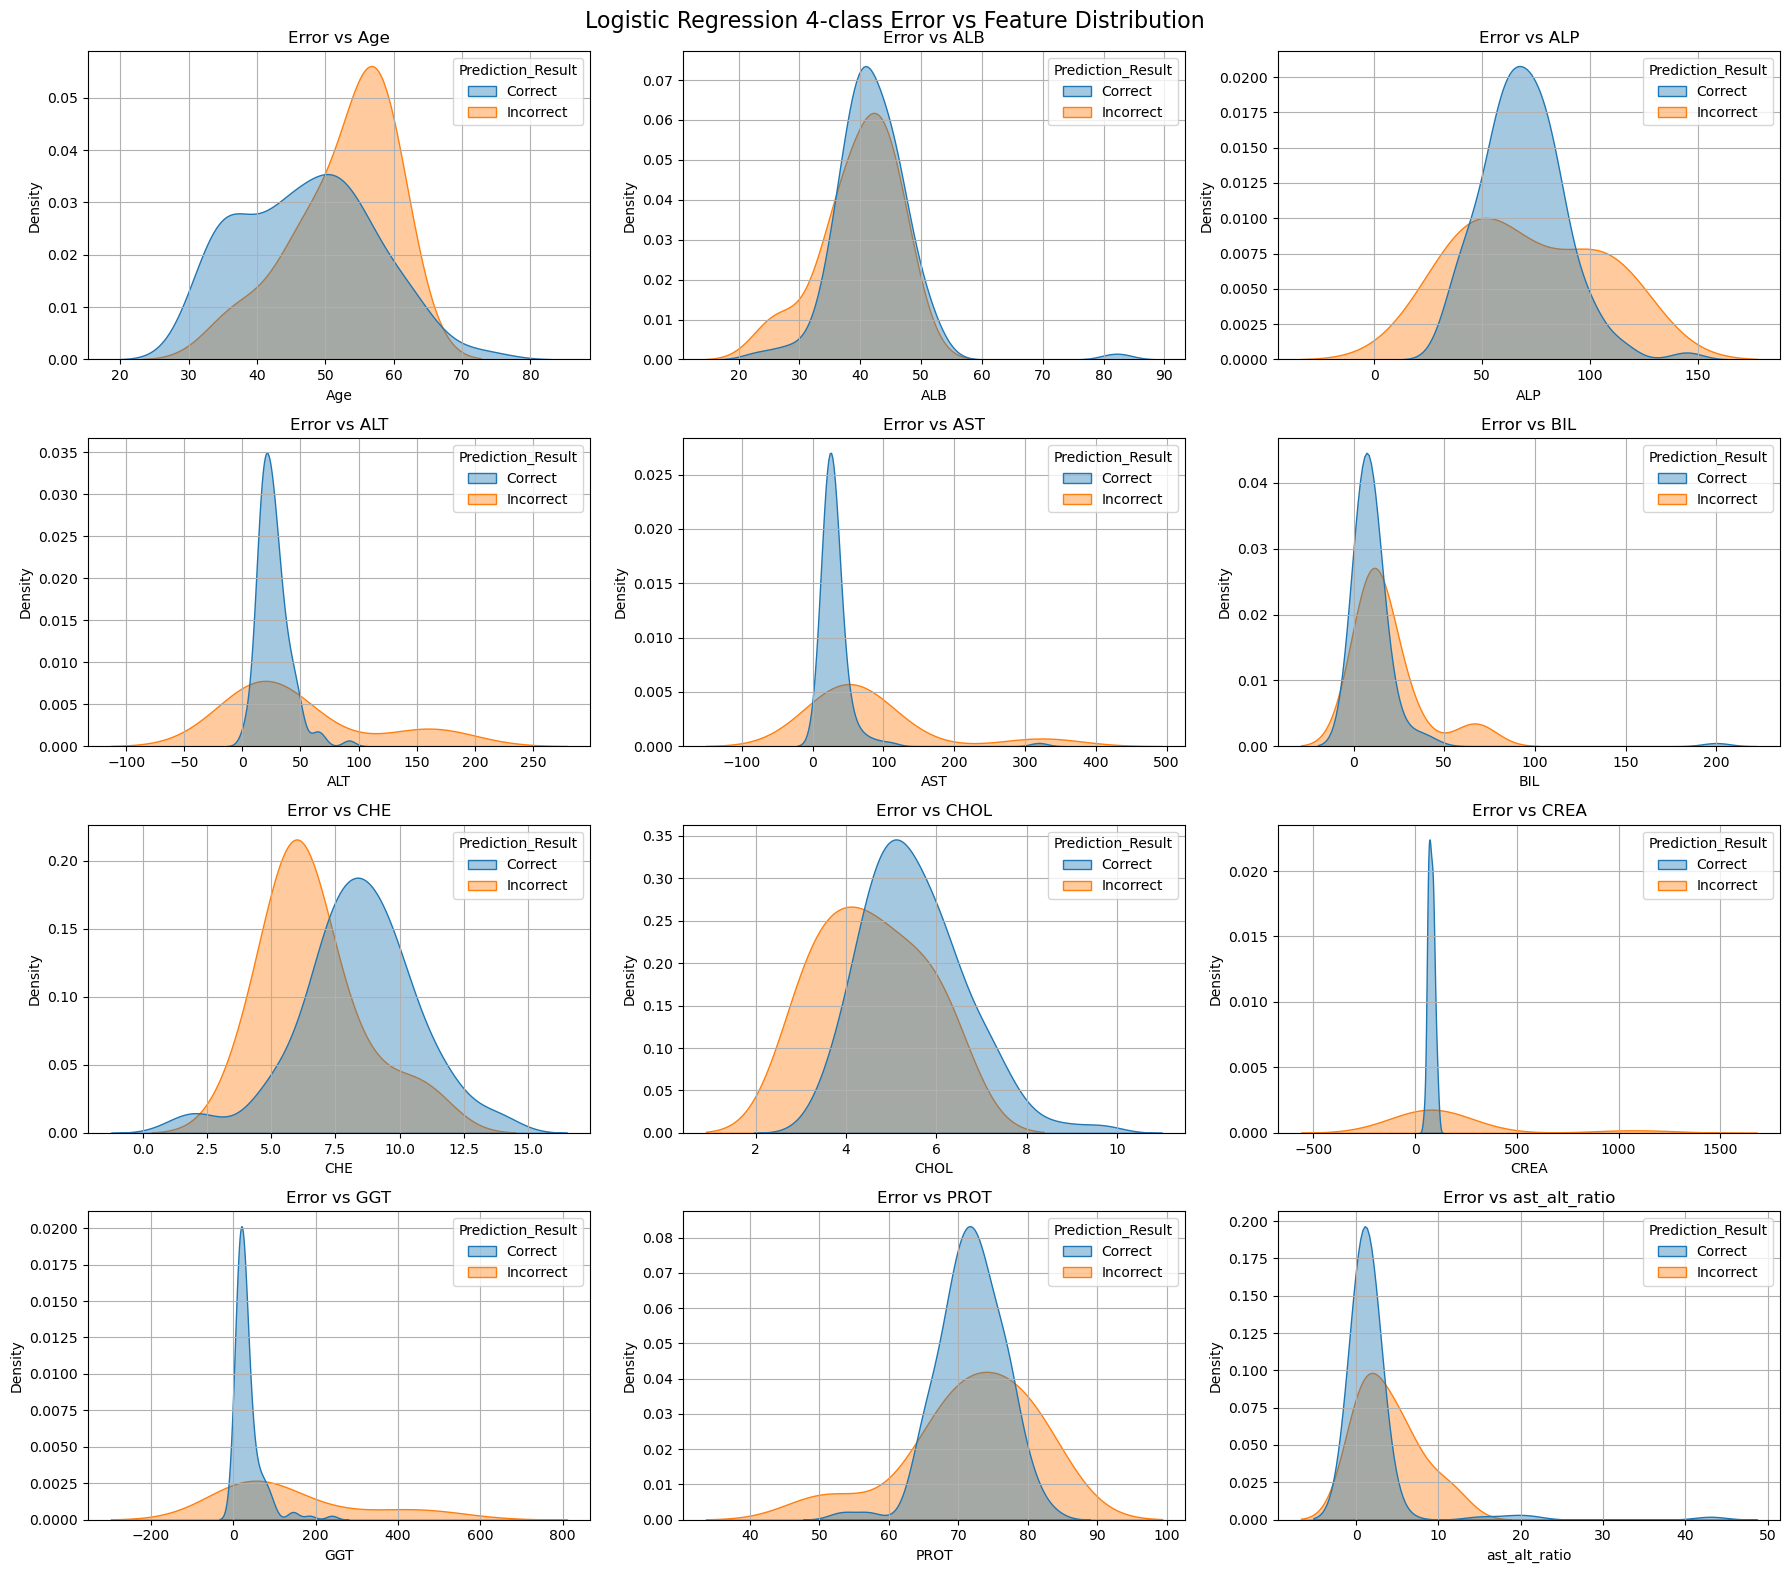

In [21]:
# creating subplots (same features and layout as the binary models)
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=log_error_df_4c,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Logistic Regression 4-class Error vs Feature Distribution',
             fontsize=16)
plt.tight_layout()
plt.show()

# Random forest

In [22]:
# defining random forest pipeline
rf_model_4c = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTENC(
        categorical_features=sex_position,
        k_neighbors=5,
        random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=200,        # number of trees
        max_depth=None,          # let trees grow fully
        min_samples_split=2,     # minimum samples to split
        min_samples_leaf=1,      # minimum samples per leaf
        max_features='sqrt',     # features considered per split
        class_weight='balanced',
        random_state=42,
        n_jobs=-1))])

# training pipeline
rf_model_4c.fit(X_train_4c, y_train_4c)

# testing pipeline
rf_preds_4c = rf_model_4c.predict(X_test_4c)

# evaluating predictions
rf_results_4c = classification_report(
    y_test_4c, rf_preds_4c, target_names=classes_4c)
print(rf_results_4c)

              precision    recall  f1-score   support

   Cirrhosis       0.60      1.00      0.75         6
    Fibrosis       0.50      0.25      0.33         4
     Healthy       0.99      0.99      0.99       107
   Hepatitis       0.33      0.20      0.25         5

    accuracy                           0.93       122
   macro avg       0.61      0.61      0.58       122
weighted avg       0.93      0.93      0.93       122



Accuracy is 93%. The model finds all 6 cirrhosis patients but only 1 of the 4 fibrosis and 1 of the 5 hepatitis patients, and wrongly flags 1 of the 107 healthy patients.

# Calibration plot - Random Forest

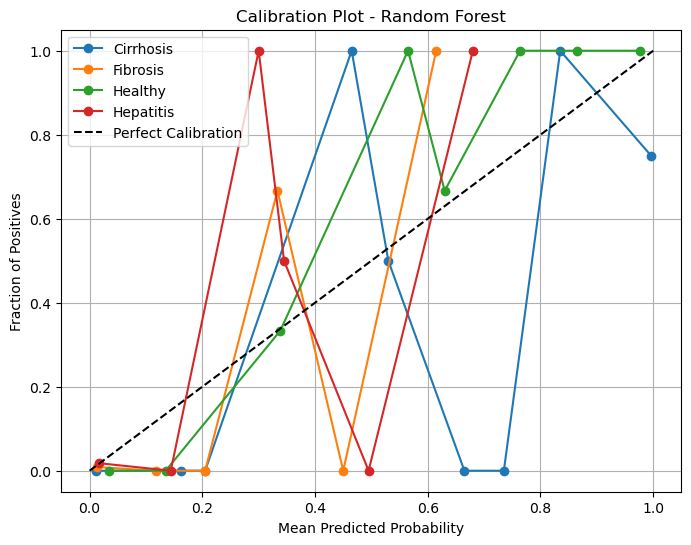

In [23]:
# getting predicted probabilities of every class from Random Forest
rf_probs_4c = rf_model_4c.predict_proba(X_test_4c)

# plotting calibration curves
plt.figure(figsize=(8, 6))

# loop through each class
for i, class_name in enumerate(classes_4c):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin_4c[:, i],
        rf_probs_4c[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=class_name)

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Random Forest')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature plot - random forest

Data preparation

In [24]:
# creating a copy of the test data
rf_error_df_4c = X_test_4c.copy()

# adding actual and predicted classes
rf_error_df_4c['Actual_Class'] = y_test_4c
rf_error_df_4c['Predicted_Class'] = rf_preds_4c

# checking if the prediction was correct or incorrect
rf_error_df_4c['Prediction_Result'] = np.where(
    y_test_4c == rf_preds_4c,
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(rf_error_df_4c['Prediction_Result'].value_counts())

Prediction_Result
Correct      114
Incorrect      8
Name: count, dtype: int64


Error plots - random forest

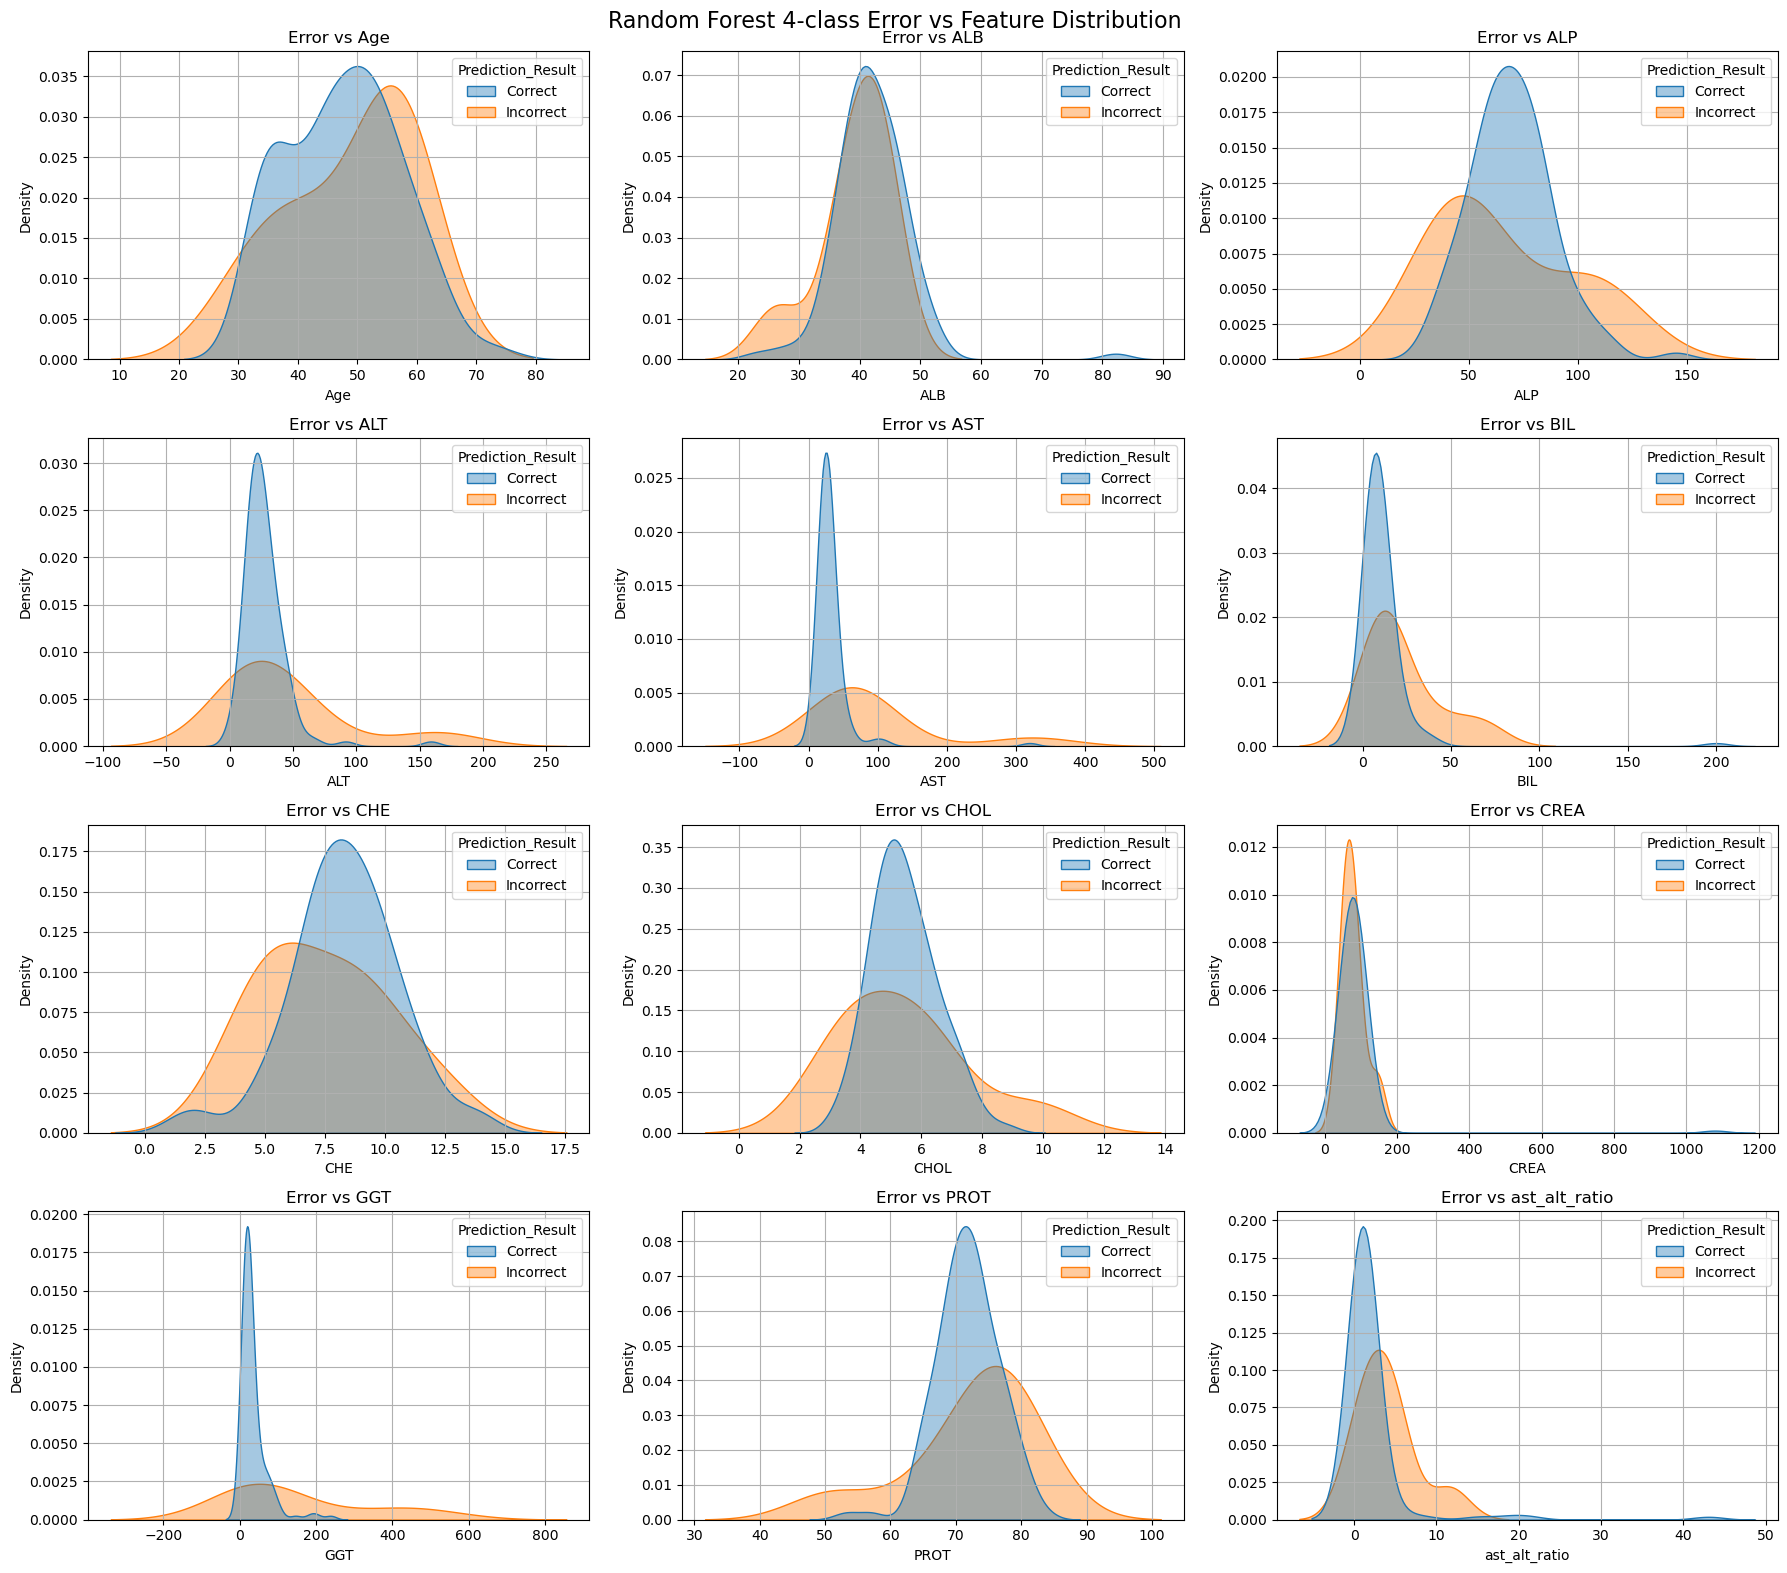

In [25]:
# creating subplots (same features and layout as the binary models)
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=rf_error_df_4c,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Random Forest 4-class Error vs Feature Distribution',
             fontsize=16)
plt.tight_layout()
plt.show()

# Decision tree

In [26]:
# defining decision tree pipeline
dt_model_4c = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTENC(
        categorical_features=sex_position,
        k_neighbors=5,
        random_state=42)),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'))])

# training model
dt_model_4c.fit(X_train_4c, y_train_4c)

# predictions
dt_preds_4c = dt_model_4c.predict(X_test_4c)

# evaluating predictions
print('Accuracy:', accuracy_score(y_test_4c, dt_preds_4c))
print(classification_report(
    y_test_4c, dt_preds_4c, target_names=classes_4c))

Accuracy: 0.9180327868852459
              precision    recall  f1-score   support

   Cirrhosis       0.50      0.83      0.62         6
    Fibrosis       0.00      0.00      0.00         4
     Healthy       0.98      0.99      0.99       107
   Hepatitis       0.33      0.20      0.25         5

    accuracy                           0.92       122
   macro avg       0.45      0.51      0.47       122
weighted avg       0.90      0.92      0.91       122



Accuracy is 92%. The tree finds 5 of the 6 cirrhosis patients and 1 of the 5 hepatitis patients, and none of the 4 fibrosis patients. It wrongly flags 1 of the 107 healthy patients.

# Calibration plot - Decision Tree

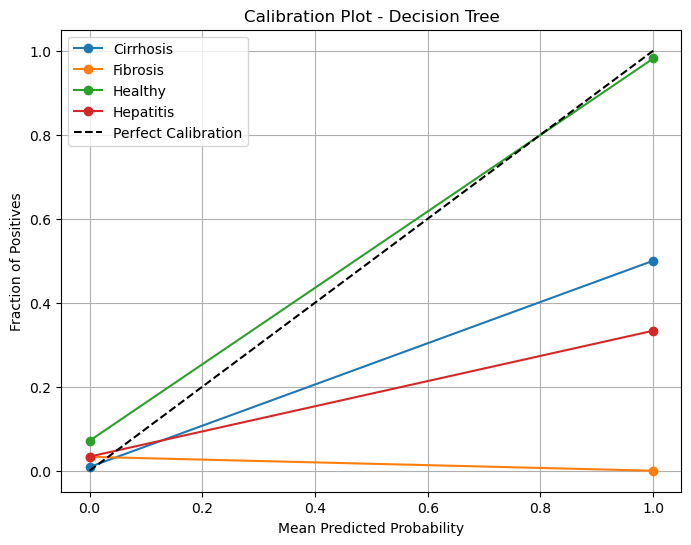

In [27]:
# getting predicted probabilities of every class from Decision Tree
dt_probs_4c = dt_model_4c.predict_proba(X_test_4c)

# plotting calibration curves
plt.figure(figsize=(8, 6))

# loop through each class
for i, class_name in enumerate(classes_4c):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin_4c[:, i],
        dt_probs_4c[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=class_name)

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Decision Tree')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# **Three-stage models: hepatitis, fibrosis or cirrhosis**

These models only see the 75 sick patients and predict which disease they have. The three classes are close to balanced (24, 21 and 30 patients), so SMOTE is not used and class weights are enough.

# Data preparation

In [28]:
# keeping the sick patients only
sick_df_3s = df[df['Category'] != 'Healthy']

# encoding the three diseases into numeric values
encoder_3s = LabelEncoder()
y_3s = encoder_3s.fit_transform(sick_df_3s['Category'])
classes_3s = encoder_3s.classes_
print(classes_3s)

# same feature columns as the binary models
X_3s = X.loc[sick_df_3s.index]

# train - test split
X_train_3s, X_test_3s, y_train_3s, y_test_3s = train_test_split(
    X_3s, y_3s, test_size=0.2, random_state=42, stratify=y_3s
)

# class counts of the training set and the test set
print(pd.Series(y_train_3s).map(dict(enumerate(classes_3s))).value_counts())
print(pd.Series(y_test_3s).map(dict(enumerate(classes_3s))).value_counts())

# binarising the test labels for the calibration plots
y_test_bin_3s = label_binarize(y_test_3s, classes=range(len(classes_3s)))

['Cirrhosis' 'Fibrosis' 'Hepatitis']
Cirrhosis    24
Hepatitis    19
Fibrosis     17
Name: count, dtype: int64
Cirrhosis    6
Hepatitis    5
Fibrosis     4
Name: count, dtype: int64


# Logistic regression

In [29]:
# defining logistic regression pipeline
# n_quantiles is set to the number of training rows as it cannot be larger
log_pipeline_3s = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transformer', QuantileTransformer(
        n_quantiles=len(X_train_3s),
        output_distribution='normal',
        random_state=42)),
    ('classifier', LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42))])

# training pipeline
log_pipeline_3s.fit(X_train_3s, y_train_3s)

# testing pipeline
log_preds_3s = log_pipeline_3s.predict(X_test_3s)

# evaluating predictions
log_results_3s = classification_report(
    y_test_3s, log_preds_3s, target_names=classes_3s)
print(log_results_3s)

              precision    recall  f1-score   support

   Cirrhosis       0.71      0.83      0.77         6
    Fibrosis       0.50      0.50      0.50         4
   Hepatitis       0.75      0.60      0.67         5

    accuracy                           0.67        15
   macro avg       0.65      0.64      0.65        15
weighted avg       0.67      0.67      0.66        15



The model names the right disease for 10 of the 15 test patients (67% accuracy): 5 of 6 cirrhosis, 2 of 4 fibrosis and 3 of 5 hepatitis.

# Calibration plot - Logistic Regression

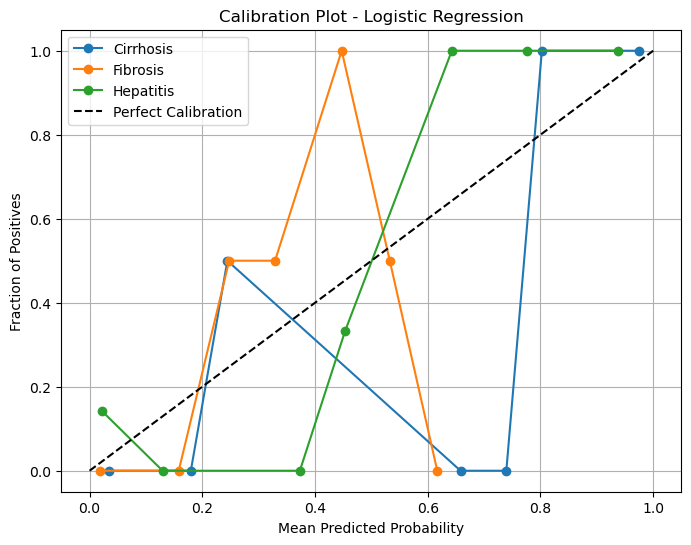

In [30]:
# getting predicted probabilities of every class from Logistic Regression
log_probs_3s = log_pipeline_3s.predict_proba(X_test_3s)

# plotting calibration curves
plt.figure(figsize=(8, 6))

# loop through each class
for i, class_name in enumerate(classes_3s):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin_3s[:, i],
        log_probs_3s[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=class_name)

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Logistic Regression')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature distribution - logistic regression

Data preparation

In [31]:
# creating a copy of the test data
log_error_df_3s = X_test_3s.copy()

# adding actual and predicted classes
log_error_df_3s['Actual_Class'] = y_test_3s
log_error_df_3s['Predicted_Class'] = log_preds_3s

# checking if the prediction was correct or incorrect
log_error_df_3s['Prediction_Result'] = np.where(
    y_test_3s == log_preds_3s,
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(log_error_df_3s['Prediction_Result'].value_counts())

Prediction_Result
Correct      10
Incorrect     5
Name: count, dtype: int64


Error plots - logistic regression

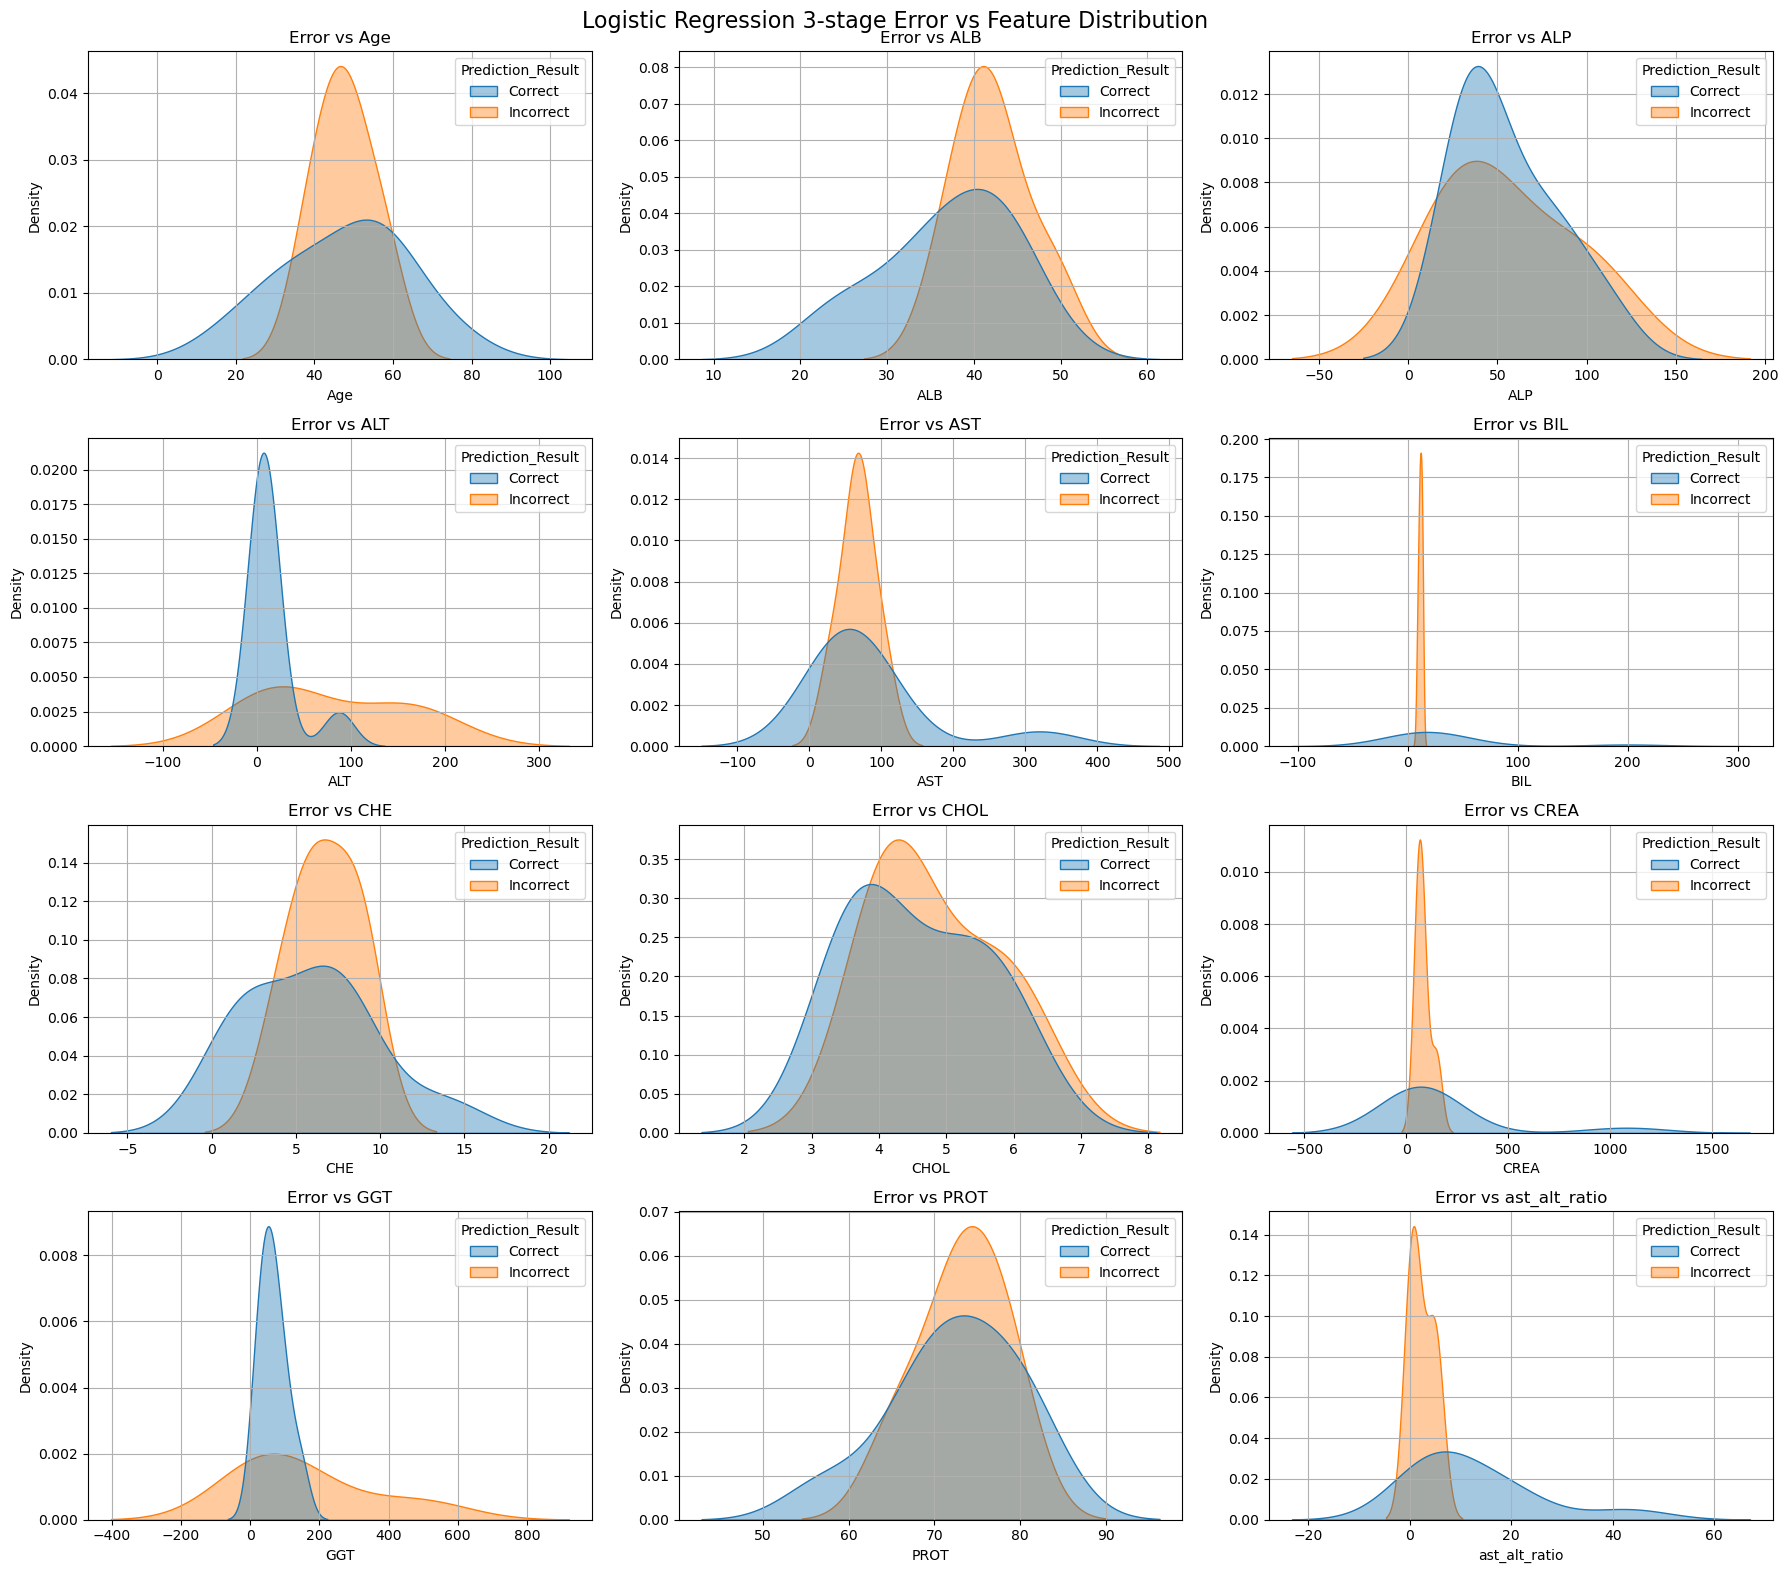

In [32]:
# creating subplots (same features and layout as the binary models)
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=log_error_df_3s,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Logistic Regression 3-stage Error vs Feature Distribution',
             fontsize=16)
plt.tight_layout()
plt.show()

# Random forest

In [33]:
# defining random forest pipeline
rf_model_3s = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        n_estimators=200,        # number of trees
        max_depth=None,          # let trees grow fully
        min_samples_split=2,     # minimum samples to split
        min_samples_leaf=1,      # minimum samples per leaf
        max_features='sqrt',     # features considered per split
        class_weight='balanced',
        random_state=42,
        n_jobs=-1))])

# training pipeline
rf_model_3s.fit(X_train_3s, y_train_3s)

# testing pipeline
rf_preds_3s = rf_model_3s.predict(X_test_3s)

# evaluating predictions
rf_results_3s = classification_report(
    y_test_3s, rf_preds_3s, target_names=classes_3s)
print(rf_results_3s)

              precision    recall  f1-score   support

   Cirrhosis       0.71      0.83      0.77         6
    Fibrosis       0.33      0.25      0.29         4
   Hepatitis       0.60      0.60      0.60         5

    accuracy                           0.60        15
   macro avg       0.55      0.56      0.55        15
weighted avg       0.57      0.60      0.58        15



The model names the right disease for 9 of the 15 test patients (60% accuracy): 5 of 6 cirrhosis, 1 of 4 fibrosis and 3 of 5 hepatitis.

# Calibration plot - Random Forest

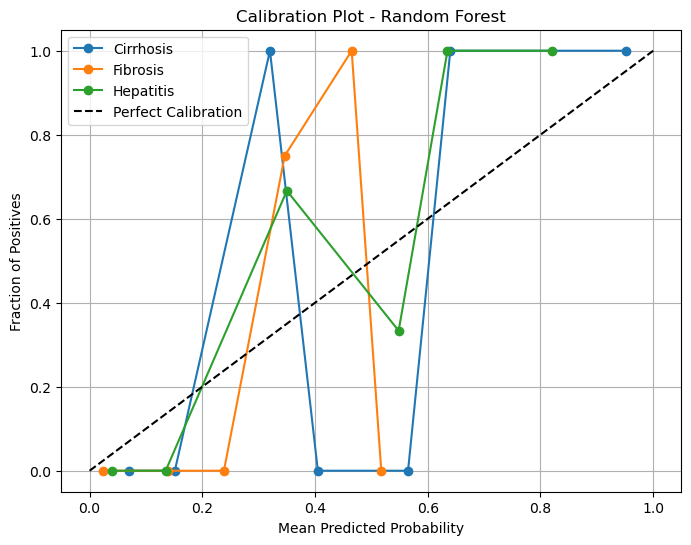

In [34]:
# getting predicted probabilities of every class from Random Forest
rf_probs_3s = rf_model_3s.predict_proba(X_test_3s)

# plotting calibration curves
plt.figure(figsize=(8, 6))

# loop through each class
for i, class_name in enumerate(classes_3s):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin_3s[:, i],
        rf_probs_3s[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=class_name)

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Random Forest')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# Error vs feature plot - random forest

Data preparation

In [35]:
# creating a copy of the test data
rf_error_df_3s = X_test_3s.copy()

# adding actual and predicted classes
rf_error_df_3s['Actual_Class'] = y_test_3s
rf_error_df_3s['Predicted_Class'] = rf_preds_3s

# checking if the prediction was correct or incorrect
rf_error_df_3s['Prediction_Result'] = np.where(
    y_test_3s == rf_preds_3s,
    'Correct',
    'Incorrect'
)

# counting correct and incorrect predictions
print(rf_error_df_3s['Prediction_Result'].value_counts())

Prediction_Result
Correct      9
Incorrect    6
Name: count, dtype: int64


Error plots - random forest

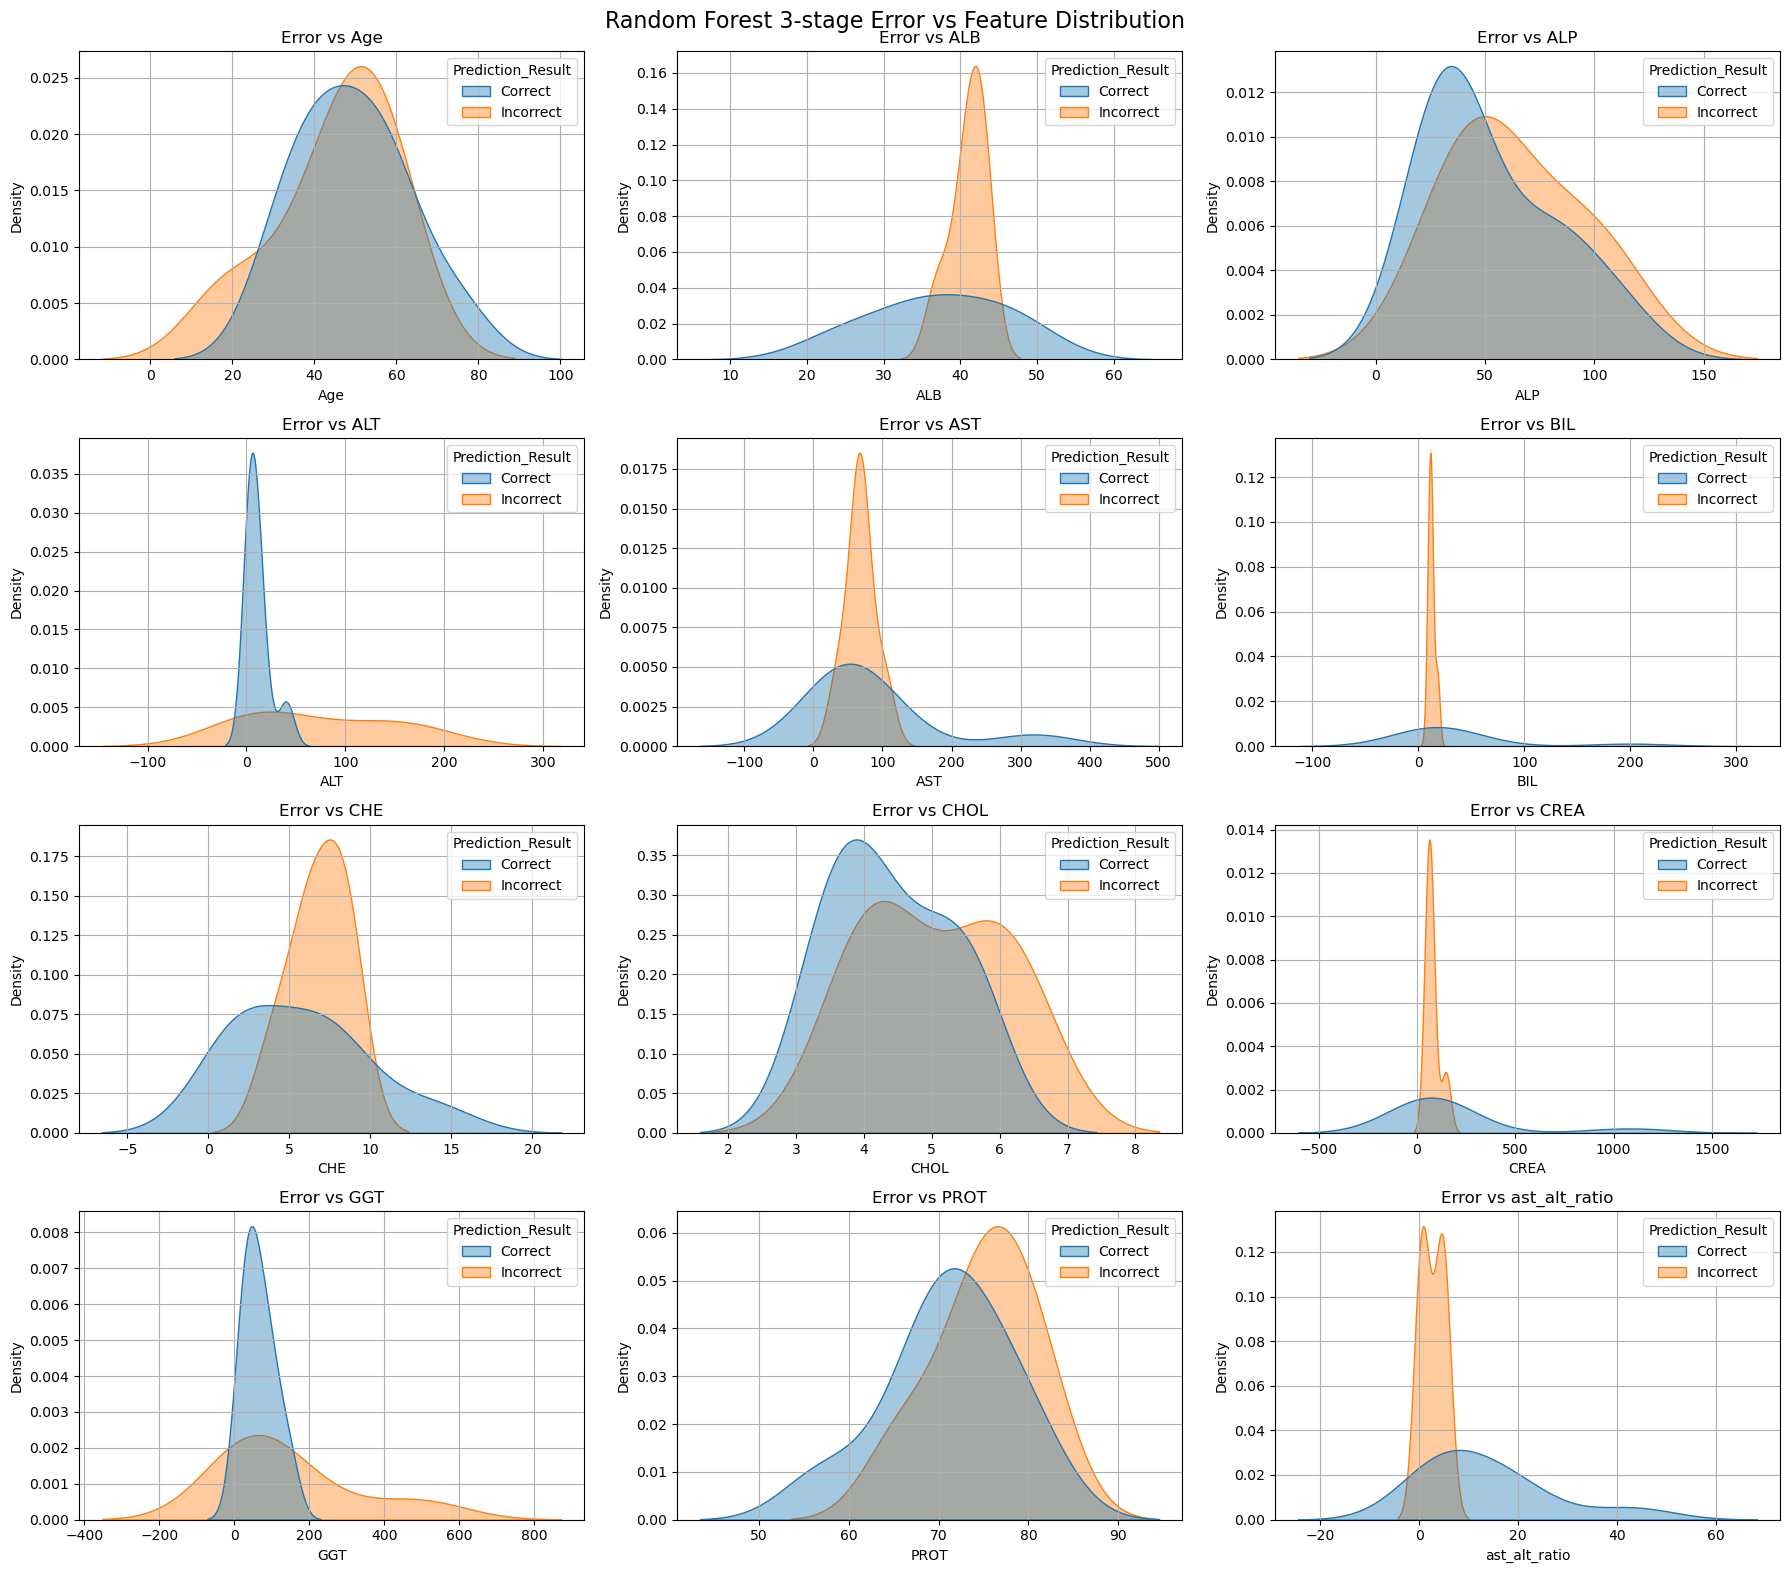

In [36]:
# creating subplots (same features and layout as the binary models)
fig, axes = plt.subplots(n_rows, plots_per_row, figsize=(18, n_rows * 4))

# flattening axes so they can be looped through easily
axes = axes.flatten()

# loop through each feature
for i, feature in enumerate(features_to_plot):

    # plotting correct vs incorrect prediction distributions
    sns.kdeplot(
        data=rf_error_df_3s,
        x=feature,
        hue='Prediction_Result',
        hue_order=['Correct', 'Incorrect'],
        fill=True,
        common_norm=False,
        alpha=0.4,
        ax=axes[i]
    )

    # formatting each plot
    axes[i].set_title(f'Error vs {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')
    axes[i].grid(True)

# removing empty subplot spaces
for j in range(len(features_to_plot), len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle('Random Forest 3-stage Error vs Feature Distribution',
             fontsize=16)
plt.tight_layout()
plt.show()

# Decision tree

In [37]:
# defining decision tree pipeline
dt_model_3s = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'))])

# training model
dt_model_3s.fit(X_train_3s, y_train_3s)

# predictions
dt_preds_3s = dt_model_3s.predict(X_test_3s)

# evaluating predictions
print('Accuracy:', accuracy_score(y_test_3s, dt_preds_3s))
print(classification_report(
    y_test_3s, dt_preds_3s, target_names=classes_3s))

Accuracy: 0.6
              precision    recall  f1-score   support

   Cirrhosis       0.75      1.00      0.86         6
    Fibrosis       0.40      0.50      0.44         4
   Hepatitis       0.50      0.20      0.29         5

    accuracy                           0.60        15
   macro avg       0.55      0.57      0.53        15
weighted avg       0.57      0.60      0.56        15



The tree names the right disease for 9 of the 15 test patients (60% accuracy): all 6 cirrhosis, 2 of 4 fibrosis and 1 of 5 hepatitis.

# Calibration plot - Decision Tree

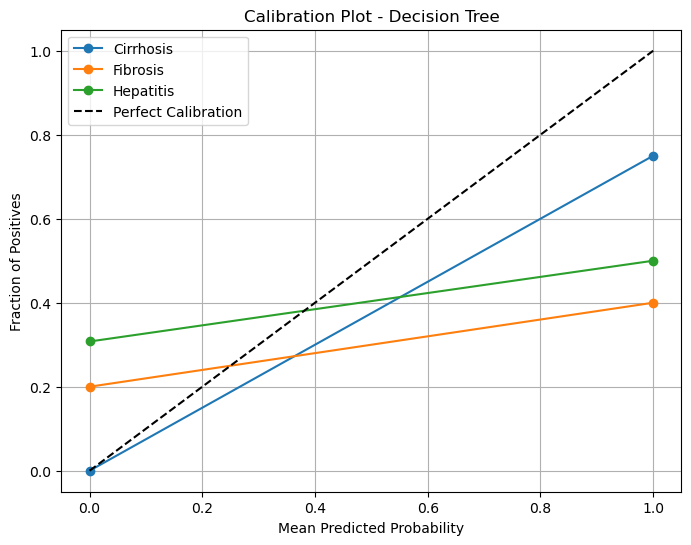

In [38]:
# getting predicted probabilities of every class from Decision Tree
dt_probs_3s = dt_model_3s.predict_proba(X_test_3s)

# plotting calibration curves
plt.figure(figsize=(8, 6))

# loop through each class
for i, class_name in enumerate(classes_3s):

    # calculate calibration curve for each class
    prob_true, prob_pred = calibration_curve(
        y_test_bin_3s[:, i],
        dt_probs_3s[:, i],
        n_bins=10,
        strategy='uniform'
    )

    # plot reliability curve
    plt.plot(prob_pred, prob_true, marker='o', label=class_name)

# perfect calibration reference line
plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Perfect Calibration')

# formatting plot
plt.title('Calibration Plot - Decision Tree')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.legend()
plt.grid(True)
plt.show()

# **Summary**

All models fill missing values with a median learned from the training rows only, so no test patient influences training. Healthy or sick is easy: all three models reach 98% accuracy with no synthetic patients. Naming the disease is much harder. With four classes and SMOTE, accuracy stays at 92% to 93% only because most patients are healthy, and macro F1 falls to 0.61 (logistic regression), 0.58 (random forest) and 0.47 (decision tree). Among the 75 sick patients only, the models name the right disease for 9 or 10 of 15 test patients (macro F1 0.65, 0.55 and 0.53). Cirrhosis is found most often, and fibrosis and hepatitis are often mixed up.

These results have limits:

- The test sets are small. The four-class test set has 6 cirrhosis, 5 hepatitis and 4 fibrosis patients, and the three-stage test set has 15 patients, so one patient changes a recall by 17 to 25 points. The binary test set has 15 sick patients, so one patient changes sick recall by about 7 points.
- The results come from a single train-test split, as in COM725.
- SMOTE builds synthetic patients from only 17 to 24 real patients per disease class, and the differences between the three models are within what one patient can change.

# **Primary analysis: nested cross-validation**

The models above were tested on one 80/20 split with 15 sick patients, so one patient changes a result by 7 to 25 points. This part is the primary analysis of the paper, set up to follow TRIPOD+AI.

- **Design.** Stratified 5-fold cross-validation repeated 10 times (the outer loop). Every patient is tested 10 times, each time by a model that never saw them.
- **Tuning.** Inside each outer training fold, a stratified 5-fold inner loop picks the settings with the lowest log loss. Log loss rewards accurate probabilities, not only the right class.
- **Imbalance.** Each model is run four ways: no correction, class weights (the primary choice), SMOTE-NC without class weights, and SMOTE-NC followed by recalibration. Class weights and SMOTE are no longer combined, as that corrects the imbalance twice.
- **Baselines.** A majority-class model (always predicts the class proportions) and a logistic regression on the AST/ALT ratio alone. APRI and FIB-4 cannot be calculated because the data have no platelet counts.
- **Leakage.** Imputation, transformation, SMOTE-NC and recalibration are all steps inside the pipeline, so they only learn from training rows.
- **Stability.** The whole procedure is repeated with five seeds (Riley and Collins, 2023). Seed 42 is the primary analysis.

All out-of-fold predictions are saved in `results/`. Every metric, plot and subgroup result below is calculated from those files, without training the models again.

## Libraries

In [ ]:
# libraries for the primary analysis. Some are already imported above,
# but they are listed again so this part can be read on its own
import os
import time
import warnings
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, log_loss, recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
)
from sklearn.preprocessing import QuantileTransformer
from sklearn.tree import DecisionTreeClassifier

# the out-of-fold predictions and the metrics are saved in this folder
Path("results").mkdir(exist_ok=True)

# hide the repeated warnings about convergence and small samples, also in
# the parallel workers that GridSearchCV starts
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

## Data and the three outcomes

The 7 suspected blood donors are removed, which leaves 608 patients. The 13 predictors are the same as in the models above.

In [ ]:
# reload the raw data so this part does not depend on the cells above
data = pd.read_csv("hcvdat0.csv").drop(columns=["Unnamed: 0"])
data["Category"] = data["Category"].str.replace(r"^[^=]*=", "", regex=True)
data = data[~data["Category"].str.contains("suspect", case=False)]
data["Category"] = data["Category"].replace("Blood Donor", "Healthy")
data = data.reset_index(drop=True)

# AST/ALT ratio. One patient has no ALT, so one ratio is missing and is
# filled by the imputer inside each pipeline
data["ast_alt_ratio"] = data["AST"] / data["ALT"]

# sex as a number (women = 0, men = 1)
data["Sex"] = (data["Sex"] == "m").astype(int)

# the 13 predictors: age, sex, ten lab values and the AST/ALT ratio.
# sex is the second column (position 1), which SMOTE-NC needs to know
predictors = [
    "Age", "Sex", "ALB", "ALP", "ALT", "AST", "BIL", "CHE", "CHOL",
    "CREA", "GGT", "PROT", "ast_alt_ratio",
]

# the three outcomes, each with its patients, their label and the order of
# the classes. The row number of each patient is kept as its id
sick = data[data["Category"] != "Healthy"]
outcomes = {
    "Healthy vs sick": (
        data.assign(label=np.where(data["Category"] == "Healthy",
                                   "Healthy", "Sick")),
        ["Healthy", "Sick"],
    ),
    "Four classes": (
        data.assign(label=data["Category"]),
        ["Healthy", "Hepatitis", "Fibrosis", "Cirrhosis"],
    ),
    "Three disease stages": (
        sick.assign(label=sick["Category"]),
        ["Hepatitis", "Fibrosis", "Cirrhosis"],
    ),
}

# number of patients in each class for every outcome
for outcome_name, (frame, classes) in outcomes.items():
    counts = frame["label"].value_counts().reindex(classes)
    print(outcome_name, counts.to_dict())

## Nested cross-validation over five seeds

For each seed and outcome: 50 outer folds, and in each one 9 tuned models (3 models x 3 ways of handling the imbalance), a recalibrated copy of the 3 SMOTE-NC models and the 2 baselines. The grids are small because the inner folds hold very few sick patients. Random forest always uses 300 trees. This cell takes about 2 hours the first time; after that the saved files are loaded.

In [ ]:
# nested cross-validation for every seed, outcome, model and way of
# handling the imbalance. Seed 42 is the primary analysis and the other
# four seeds repeat everything to check stability. Each finished run is
# saved, and a saved run is loaded instead of being trained again
oof = {}
for seed, outcome_name in product([42, 7, 123, 2024, 31415], outcomes):
    frame, classes = outcomes[outcome_name]
    file_name = outcome_name.replace(" ", "_").lower()
    path = Path("results") / f"oof_{file_name}_seed{seed}.csv.gz"
    if path.exists():
        oof[(seed, outcome_name)] = pd.read_csv(path)
        print(f"seed {seed}, {outcome_name}: loaded from {path}")
        continue

    start = time.time()
    X = frame[predictors]
    y = frame["label"].to_numpy()
    rows = []

    # outer loop: stratified 5-fold cross-validation repeated 10 times,
    # so every patient is tested 10 times by a model that never saw them
    outer = RepeatedStratifiedKFold(
        n_splits=5, n_repeats=10, random_state=seed
    )
    for fold, (train, test) in enumerate(outer.split(X, y)):
        X_train, y_train = X.iloc[train], y[train]
        X_test = X.iloc[test]

        # inner loop for tuning: stratified 5-fold CV on the outer
        # training rows only, scored by log loss
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        fitted_models = []

        for model_name, arm in product(
            ["Logistic regression", "Random forest", "Decision tree"],
            ["No correction", "Class weights", "SMOTE-NC"],
        ):
            # class weights make the rare classes count more. They are only
            # used in the "Class weights" arm, never together with SMOTE-NC
            weight = "balanced" if arm == "Class weights" else None

            # every pipeline first fills missing values with the median of
            # the training rows
            steps = [("imputer", SimpleImputer(strategy="median"))]

            # SMOTE-NC makes synthetic patients for the rare classes from
            # the training rows only. Sex (position 1) stays 0 or 1
            if arm == "SMOTE-NC":
                steps.append(("smote", SMOTENC(
                    categorical_features=[1], k_neighbors=5,
                    random_state=seed,
                )))

            # the model and its small grid of settings to tune
            if model_name == "Logistic regression":
                # skewed lab values are mapped to a normal shape first
                steps.append(("transformer", QuantileTransformer(
                    n_quantiles=100, output_distribution="normal",
                    random_state=seed,
                )))
                steps.append(("classifier", LogisticRegression(
                    penalty="l2", max_iter=5000, class_weight=weight,
                    random_state=seed,
                )))
                grid = {"classifier__C": [0.01, 0.1, 1, 10, 100]}
            elif model_name == "Random forest":
                steps.append(("classifier", RandomForestClassifier(
                    n_estimators=300, max_features="sqrt",
                    class_weight=weight, random_state=seed,
                )))
                grid = {
                    "classifier__max_depth": [None, 5],
                    "classifier__min_samples_leaf": [1, 3, 5],
                }
            else:
                steps.append(("classifier", DecisionTreeClassifier(
                    class_weight=weight, random_state=seed,
                )))
                grid = {
                    "classifier__max_depth": [2, 3, 4, 5, None],
                    "classifier__min_samples_leaf": [1, 3, 5],
                }

            # tune on the inner folds by log loss, then refit the best
            # settings on the whole outer training fold
            search = GridSearchCV(
                ImbPipeline(steps), grid, cv=inner,
                scoring="neg_log_loss", n_jobs=-1,
            )
            search.fit(X_train, y_train)
            params = str(search.best_params_)
            fitted_models.append(
                (model_name, arm, search.best_estimator_, X_test, params)
            )

            # recalibration after SMOTE-NC: a sigmoid correction learnt on
            # held-out parts of the outer training fold, never the test fold
            if arm == "SMOTE-NC":
                calibrated = CalibratedClassifierCV(
                    search.best_estimator_, method="sigmoid", cv=inner,
                    n_jobs=-1,
                )
                calibrated.fit(X_train, y_train)
                fitted_models.append((
                    model_name, "SMOTE-NC + recalibration", calibrated,
                    X_test, params,
                ))

        # baseline 1: always predicts the class proportions of the
        # training rows
        majority = DummyClassifier(strategy="prior").fit(X_train, y_train)
        fitted_models.append(
            ("Majority class", "Reference", majority, X_test, "")
        )

        # baseline 2: logistic regression on the AST/ALT ratio alone
        ratio_model = ImbPipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("transformer", QuantileTransformer(
                n_quantiles=100, output_distribution="normal",
                random_state=seed,
            )),
            ("classifier", LogisticRegression(
                max_iter=5000, random_state=seed,
            )),
        ]).fit(X_train[["ast_alt_ratio"]], y_train)
        fitted_models.append((
            "AST/ALT ratio only", "Reference", ratio_model,
            X_test[["ast_alt_ratio"]], "",
        ))

        # keep the predicted probability of every class for every test
        # patient, in the class order of this outcome
        for model_name, arm, fitted, X_part, params in fitted_models:
            probabilities = pd.DataFrame(
                fitted.predict_proba(X_part), columns=fitted.classes_
            )[classes].add_prefix("p_")
            probabilities["patient"] = frame.index[test]
            probabilities["true"] = y[test]
            probabilities["Sex"] = X_test["Sex"].to_numpy()
            probabilities["model"] = model_name
            probabilities["arm"] = arm
            probabilities["params"] = params
            probabilities["repeat"] = fold // 5
            probabilities["seed"] = seed
            rows.append(probabilities)

    oof[(seed, outcome_name)] = pd.concat(rows, ignore_index=True)
    oof[(seed, outcome_name)].to_csv(path, index=False)
    print(f"seed {seed}, {outcome_name}: "
          f"{(time.time() - start) / 60:.1f} minutes")

## Sensitivity analysis: fixed settings under repeated cross-validation

The pipelines from the single 80/20 split above, with their fixed settings, are tested with stratified 5-fold cross-validation repeated five times. This shows how much the single split and the lack of tuning changed the earlier results.

In [ ]:
# sensitivity analysis: the exact pipelines from the single 80/20 split
# above (fixed settings, no tuning, class weights, and SMOTE-NC for the
# four classes only), tested with stratified 5-fold CV repeated 5 times
sensitivity = {}
for outcome_name, (frame, classes) in outcomes.items():
    X = frame[predictors]
    y = frame["label"].to_numpy()
    rows = []
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

    for fold, (train, test) in enumerate(outer.split(X, y)):
        for model_name in ["Logistic regression", "Random forest",
                           "Decision tree"]:
            # same steps and settings as the models trained earlier
            steps = [("imputer", SimpleImputer(strategy="median"))]
            if outcome_name == "Four classes":
                steps.append(("smote", SMOTENC(
                    categorical_features=[1], k_neighbors=5, random_state=42,
                )))
            if model_name == "Logistic regression":
                steps.append(("transformer", QuantileTransformer(
                    n_quantiles=100, output_distribution="normal",
                    random_state=42,
                )))
                steps.append(("classifier", LogisticRegression(
                    penalty="l2", C=1.0, max_iter=1000,
                    class_weight="balanced", random_state=42,
                )))
            elif model_name == "Random forest":
                steps.append(("classifier", RandomForestClassifier(
                    n_estimators=200, max_features="sqrt",
                    class_weight="balanced", random_state=42, n_jobs=-1,
                )))
            else:
                steps.append(("classifier", DecisionTreeClassifier(
                    class_weight="balanced", random_state=42,
                )))

            fitted = ImbPipeline(steps).fit(X.iloc[train], y[train])
            probabilities = pd.DataFrame(
                fitted.predict_proba(X.iloc[test]), columns=fitted.classes_
            )[classes].add_prefix("p_")
            probabilities["patient"] = frame.index[test]
            probabilities["true"] = y[test]
            probabilities["Sex"] = X["Sex"].iloc[test].to_numpy()
            probabilities["model"] = model_name
            probabilities["arm"] = "Fixed settings"
            probabilities["repeat"] = fold // 5
            rows.append(probabilities)

    sensitivity[outcome_name] = pd.concat(rows, ignore_index=True)
    print(outcome_name, "done")

## Performance with 95% confidence intervals

- **AUROC:** how well the model ranks a patient with the disease above one without it (0.5 = chance, 1 = perfect). For several classes, each class against the rest, then the average.
- **Brier score:** mean squared error of the probabilities (0 = perfect). With several classes it is summed over the classes, so it runs from 0 to 2.
- **Log loss:** the tuning target; lower is better.
- **Macro F1, balanced accuracy, recall:** from the class with the highest probability.
- **Calibration intercept and slope** (healthy vs sick only): ideal values are 0 and 1. A slope below 1 means the predicted risks are too extreme, above 1 too cautious.

The fold standard deviations are not used as intervals, because the folds share training patients and their spread underestimates the uncertainty (Bates, Hastie and Tibshirani, 2024). The bootstrap keeps the trained models fixed, so the intervals may still be slightly narrow.

In [ ]:
# everything that is evaluated: the primary analysis (seed 42) with
# confidence intervals, the same predictions split by sex, the other four
# seeds (estimates only) and the sensitivity analysis
evaluations = []
for (seed, outcome_name), frame in oof.items():
    evaluations.append((outcome_name, "All", str(seed), frame, seed == 42))
    if seed == 42:
        # by sex, only the primary settings and the baselines
        keep = frame["arm"].isin(
            ["No correction", "Class weights", "Reference"]
        )
        for sex_code, sex_label in [(0, "Women"), (1, "Men")]:
            subset = frame[keep & (frame["Sex"] == sex_code)]
            evaluations.append((outcome_name, sex_label, "42", subset, True))
for outcome_name, frame in sensitivity.items():
    evaluations.append((outcome_name, "All", "Fixed 5x5", frame, True))
print("Groups to evaluate:", len(evaluations))

In [ ]:
# metrics for every model and setting. The estimate is the metric on each
# repeat's out-of-fold predictions, averaged over the repeats. For the
# 95% confidence interval, 1000 bootstrap samples are drawn: patients are
# resampled with replacement within each class (so no class disappears)
# and one repeat is picked at random, so the interval covers both the
# patients and the way they were split. Takes about 15 minutes
rng = np.random.default_rng(42)
metric_rows = []
start = time.time()

for outcome_name, group, seed, frame, with_ci in evaluations:
    classes = outcomes[outcome_name][1]
    prob_columns = ["p_" + c for c in classes]

    for (model_name, arm), config in frame.groupby(["model", "arm"],
                                                   sort=False):
        # one table per repeat, with the patients in the same order
        repeats = [r.sort_values("patient")
                   for _, r in config.groupby("repeat")]
        y = repeats[0]["true"].to_numpy()
        probabilities = [r[prob_columns].to_numpy() for r in repeats]

        # draws: every repeat on all patients (for the estimate), then the
        # bootstrap samples (for the confidence interval)
        draws = [(r, np.arange(len(y)), "estimate")
                 for r in range(len(repeats))]
        if with_ci:
            class_rows = [np.flatnonzero(y == c) for c in classes]
            class_rows = [rows for rows in class_rows if len(rows) > 0]
            for _ in range(1000):
                patients = np.concatenate(
                    [rng.choice(rows, size=len(rows)) for rows in class_rows]
                )
                draws.append(
                    (rng.integers(len(repeats)), patients, "bootstrap")
                )

        for repeat, patients, kind in draws:
            y_draw = y[patients]
            p = probabilities[repeat][patients]
            one_hot = (y_draw[:, None] == np.array(classes)).astype(float)
            predicted = np.array(classes)[p.argmax(axis=1)]
            values = {}

            # AUROC: how well sick patients are ranked above healthy ones
            # (0.5 = chance). For several classes: one class against the
            # rest, then the average. Brier: mean squared error of the
            # probabilities, summed over the classes when there are more
            # than two
            if len(classes) == 2:
                values["AUROC"] = roc_auc_score(one_hot[:, 1], p[:, 1])
                values["Brier"] = np.mean((p[:, 1] - one_hot[:, 1]) ** 2)
            else:
                values["AUROC"] = roc_auc_score(
                    one_hot, p, average="macro", multi_class="ovr"
                )
                values["Brier"] = np.mean(np.sum((p - one_hot) ** 2, axis=1))
            values["Log loss"] = log_loss(y_draw, p, labels=classes)

            # metrics from the class with the highest probability
            values["Macro F1"] = f1_score(
                y_draw, predicted, labels=classes, average="macro",
                zero_division=0,
            )
            values["Balanced accuracy"] = balanced_accuracy_score(
                y_draw, predicted
            )
            recalls = recall_score(
                y_draw, predicted, labels=classes, average=None,
                zero_division=0,
            )
            for class_name, recall in zip(classes, recalls):
                values[f"Recall {class_name}"] = recall

            # calibration intercept and slope for healthy vs sick. The
            # slope is a logistic regression of the true outcome on the
            # logit of the predicted risk (ideal 1). The intercept is the
            # same model with the slope fixed at 1 (ideal 0). A model that
            # gives everyone the same risk has neither
            if len(classes) == 2:
                risk = np.clip(p[:, 1], 1e-6, 1 - 1e-6)
                logit = np.log(risk / (1 - risk))
                if np.ptp(logit) > 1e-9:
                    values["Calibration slope"] = sm.GLM(
                        one_hot[:, 1], sm.add_constant(logit),
                        family=sm.families.Binomial(),
                    ).fit().params[1]
                    values["Calibration intercept"] = sm.GLM(
                        one_hot[:, 1], np.ones_like(logit), offset=logit,
                        family=sm.families.Binomial(),
                    ).fit().params[0]

            metric_rows.append({
                "Outcome": outcome_name, "Group": group, "Seed": seed,
                "Model": model_name, "Imbalance handling": arm,
                "Draw": kind, **values,
            })

metrics = pd.DataFrame(metric_rows)
print(f"{len(metrics)} rows, {(time.time() - start) / 60:.1f} minutes")

In [ ]:
# summary table: the estimate (mean over the repeats) and the 2.5th and
# 97.5th percentiles of the bootstrap samples, saved for the paper
metric_names = [c for c in metrics.columns if c not in
                ["Outcome", "Group", "Seed", "Model", "Imbalance handling",
                 "Draw"]]
keys = ["Outcome", "Group", "Seed", "Model", "Imbalance handling"]
estimates = (metrics[metrics["Draw"] == "estimate"]
             .groupby(keys, sort=False)[metric_names].mean())
lower = (metrics[metrics["Draw"] == "bootstrap"]
         .groupby(keys, sort=False)[metric_names].quantile(0.025))
upper = (metrics[metrics["Draw"] == "bootstrap"]
         .groupby(keys, sort=False)[metric_names].quantile(0.975))
summary = estimates.join(lower.add_suffix(" low")).join(
    upper.add_suffix(" high"))
summary.to_csv("results/metrics_summary.csv")

# readable version: "estimate (lower to upper)", or the estimate alone
# where no interval was calculated
readable = estimates.round(3).astype(str)
for name in metric_names:
    has_ci = lower[name].reindex(estimates.index).notna()
    readable.loc[has_ci, name] = (
        estimates.loc[has_ci, name].map("{:.3f}".format) + " ("
        + lower[name].reindex(estimates.index)[has_ci].map("{:.3f}".format)
        + " to "
        + upper[name].reindex(estimates.index)[has_ci].map("{:.3f}".format)
        + ")"
    )
readable = readable.replace("nan", "")
pd.set_option("display.max_colwidth", 30)
print("Saved results/metrics_summary.csv")

### Primary results (seed 42)

In [ ]:
# primary results (seed 42, all patients) with 95% confidence intervals
main_columns = ["AUROC", "Brier", "Log loss", "Macro F1",
                "Balanced accuracy"]
for outcome_name, (frame, classes) in outcomes.items():
    table = readable.loc[(outcome_name, "All", "42")]
    columns = main_columns + [f"Recall {c}" for c in classes]
    if outcome_name == "Healthy vs sick":
        columns += ["Calibration intercept", "Calibration slope"]
    print(outcome_name)
    display(table[columns])

## Calibration plots

In [ ]:
# calibration plots. Each patient's probability is averaged over the ten
# repeats, then patients are grouped into bins of equal size by their
# predicted risk. A well-calibrated model follows the dashed diagonal.
# Ten bins for healthy vs sick, five for the multiclass outcomes, where
# each class is checked against the rest
for outcome_name, (frame, classes) in outcomes.items():
    averaged = (oof[(42, outcome_name)]
                .groupby(["model", "arm", "patient", "true"])
                [["p_" + c for c in classes]].mean().reset_index())
    plot_classes = classes[1:] if len(classes) == 2 else classes
    n_bins = 10 if len(classes) == 2 else 5
    model_names = ["Logistic regression", "Random forest", "Decision tree"]
    fig, axes = plt.subplots(
        len(model_names), len(plot_classes),
        figsize=(4.2 * len(plot_classes), 3.8 * len(model_names)),
        squeeze=False,
    )
    for row, model_name in enumerate(model_names):
        for col, class_name in enumerate(plot_classes):
            ax = axes[row, col]
            for arm in ["No correction", "Class weights", "SMOTE-NC",
                        "SMOTE-NC + recalibration"]:
                picked = averaged[(averaged["model"] == model_name)
                                  & (averaged["arm"] == arm)]
                risk = picked["p_" + class_name]
                observed = (picked["true"] == class_name).astype(int)
                bins = pd.qcut(risk, q=n_bins, duplicates="drop")
                points = (pd.DataFrame({"risk": risk, "observed": observed})
                          .groupby(bins, observed=True).mean())
                ax.plot(points["risk"], points["observed"], marker="o",
                        label=arm)
            ax.plot([0, 1], [0, 1], linestyle="--", color="black")
            ax.set_title(f"{model_name}: {class_name}", fontsize=10)
            ax.set_xlabel("Mean predicted probability")
            ax.set_ylabel("Observed proportion")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"Calibration, {outcome_name} (out-of-fold, seed 42)")
    fig.tight_layout()
    file_name = outcome_name.replace(" ", "_").lower()
    fig.savefig(f"results/calibration_{file_name}.png", dpi=150)
    plt.show()

## Performance by sex

TRIPOD+AI asks for performance in key groups. Men and women are reported separately because men have higher liver enzymes even when healthy (`stats.ipynb`).

In [ ]:
# performance for women and men separately (seed 42). Only no correction,
# class weights and the baselines are shown. The groups are small (4 women
# with hepatitis, 8 with fibrosis), so these results are descriptive
for outcome_name, (frame, classes) in outcomes.items():
    # number of patients of each class in each sex
    print(outcome_name)
    print(pd.crosstab(frame["Sex"].map({0: "Women", 1: "Men"}),
                      frame["label"]).reindex(columns=classes))
    table = pd.concat({
        sex: readable.loc[(outcome_name, sex, "42")]
        for sex in ["Women", "Men"]
    })
    display(table[["AUROC", "Brier", "Macro F1", "Balanced accuracy"]])

## Stability across five seeds

In [ ]:
# stability over the five seeds: the estimate for each seed, then the
# mean, lowest and highest value. A small range means a stable result
per_seed = (estimates.reset_index()
            .query("Group == 'All' and Seed != 'Fixed 5x5'"))
per_seed.to_csv("results/stability_by_seed.csv", index=False)
stability = (per_seed
             .groupby(["Outcome", "Model", "Imbalance handling"],
                      sort=False)[["AUROC", "Brier", "Macro F1"]]
             .agg(["mean", "min", "max"]).round(3))
for outcome_name in outcomes:
    print(outcome_name)
    display(stability.loc[outcome_name])

In [ ]:
# instability of individual predictions (Riley and Collins, 2023): how
# much one patient's predicted risk of being sick changes between the
# five seeds, for the class-weighted models on healthy vs sick
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
model_names = ["Logistic regression", "Random forest", "Decision tree"]
for ax, model_name in zip(axes, model_names):
    risks = {}
    for seed in [42, 7, 123, 2024, 31415]:
        frame = oof[(seed, "Healthy vs sick")]
        picked = frame[(frame["model"] == model_name)
                       & (frame["arm"] == "Class weights")]
        risks[seed] = picked.groupby("patient")["p_Sick"].mean()
    risks = pd.DataFrame(risks)
    for seed in [7, 123, 2024, 31415]:
        ax.scatter(risks[42], risks[seed], s=8, alpha=0.4)
    spread = risks.std(axis=1)
    ax.plot([0, 1], [0, 1], linestyle="--", color="black")
    ax.set_title(f"{model_name}\nmedian SD = {spread.median():.3f}, "
                 f"max SD = {spread.max():.3f}", fontsize=10)
    ax.set_xlabel("Predicted risk, seed 42")
    ax.set_ylabel("Predicted risk, other seeds")
fig.suptitle("Prediction instability across five seeds "
             "(healthy vs sick, class weights)")
fig.tight_layout()
fig.savefig("results/instability_healthy_vs_sick.png", dpi=150)
plt.show()

## Sensitivity analysis results

In [ ]:
# sensitivity analysis: the fixed-setting pipelines from the single split,
# under stratified 5-fold CV repeated 5 times, with 95% intervals
for outcome_name in outcomes:
    print(outcome_name)
    display(readable.loc[(outcome_name, "All", "Fixed 5x5")]
            [["AUROC", "Brier", "Macro F1", "Balanced accuracy"]])